# Chapter 4: Higher-Order Differential Equations
## Complete Instructor Interactive Notebook

In [ ]:
import base64
import importlib.util
import platform
import sys

_REQUIRED = ["numpy", "matplotlib", "scipy", "sympy", "ipywidgets"]
_missing = [name for name in _REQUIRED if importlib.util.find_spec(name) is None]

print(f"Python {sys.version.split()[0]} on {platform.system()}")
if _missing:
    print("Missing package(s):", ", ".join(_missing))
    print("Install with: python -m pip install -r requirements.txt")
else:
    print("Notebook environment is ready.")

import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

from scipy.integrate import solve_ivp, cumulative_trapezoid
from scipy.linalg import expm
from IPython.display import display, Markdown, Math, clear_output

try:
    import ipywidgets as widgets
    from ipywidgets import ToggleButton, Output, VBox, Layout, FloatSlider, IntSlider, Dropdown, interact
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False

    def FloatSlider(*args, value=0.0, **kwargs):
        return value

    def IntSlider(*args, value=0, **kwargs):
        return value

    def Dropdown(*args, value=None, options=None, **kwargs):
        if value is not None:
            return value
        return options[0] if options else None

    def interact(function, **kwargs):
        values = {key: getattr(obj, "value", obj) for key, obj in kwargs.items()}
        function(**values)
        return None

plt.rcParams["figure.figsize"] = (9, 5.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11


def safe_solve(rhs, t_span, y0, points=700, **kwargs):
    t_eval = np.linspace(t_span[0], t_span[1], points)
    return solve_ivp(rhs, t_span, y0, t_eval=t_eval, **kwargs)


def _reveal_button(encoded_answer, label="Reveal solution"):
    if not WIDGETS_AVAILABLE:
        display(Markdown(
            "**Reveal button unavailable.** Install `ipywidgets`, restart the kernel, "
            "and run this cell again."
        ))
        return

    button = ToggleButton(
        value=False,
        description=label,
        button_style="info",
        icon="eye",
        layout=Layout(width="190px", height="40px")
    )
    out = Output(layout=Layout(width="98%", border="1px solid #dddddd", padding="10px"))

    def _toggle(change):
        with out:
            clear_output()
            if change["new"]:
                answer = base64.b64decode(encoded_answer).decode("utf-8")
                display(Markdown(answer))
                button.description = "Hide solution"
                button.icon = "eye-slash"
            else:
                button.description = label
                button.icon = "eye"

    button.observe(_toggle, names="value")
    display(VBox([button, out]))


def _show_problem(number, equation_latex, question_markdown, encoded_answer):
    display(Markdown(f"### Classroom Checkpoint {number}"))
    if equation_latex:
        display(Math(r"\displaystyle " + equation_latex))
    if question_markdown:
        display(Markdown(question_markdown))
    _reveal_button(encoded_answer, label=f"Reveal #{number}")

def show_41_checkpoint():
    _show_problem(
        1,
        r"a_n(x)y^{(n)}+\cdots+a_1(x)y'+a_0(x)y=0",
        "Suppose all initial data at $x=x_0$ are zero and the hypotheses of the linear existence--uniqueness theorem hold. Why must the solution be identically zero? Explain using the theorem rather than by solving the ODE.",
        "IyMjIFNvbHV0aW9uCgpUaGUgemVybyBmdW5jdGlvbiBzYXRpc2ZpZXMgYm90aCB0aGUgaG9tb2dlbmVvdXMgZXF1YXRpb24gYW5kIHRoZSB6ZXJvIGluaXRpYWwgZGF0YS4KClN1cHBvc2UgYSBzZWNvbmQgc29sdXRpb24gZXhpc3RlZCB3aXRoIHRoZSBzYW1lIGluaXRpYWwgZGF0YS4gVGhlIGV4aXN0ZW5jZS0tdW5pcXVlbmVzcyB0aGVvcmVtIGZvciBhIGxpbmVhciAkbiR0aC1vcmRlciBJVlAgc2F5cyB0aGF0IHRoZSBzcGVjaWZpZWQgaW5pdGlhbCBkYXRhIGRldGVybWluZSBleGFjdGx5IG9uZSBzb2x1dGlvbiBvbiB0aGUgaW50ZXJ2YWwgd2hlcmUgdGhlIG5vcm1hbGl6ZWQgY29lZmZpY2llbnRzIGFyZSBjb250aW51b3VzLgoKVGhlcmVmb3JlIG5vIHNlY29uZCBzb2x1dGlvbiBjYW4gZXhpc3QsIGFuZAoKJCQKXGJveGVke3koeClcZXF1aXYgMH0KJCQKCmlzIHRoZSB1bmlxdWUgc29sdXRpb24uCgpUaGlzIGlzIG9uZSByZWFzb24gdGhlIHVuaXF1ZW5lc3MgdGhlb3JlbSBpcyBzbyB1c2VmdWw6IGl0IGFsbG93cyB1cyB0byBkcmF3IGEgY29uY2x1c2lvbiB3aXRob3V0IHNvbHZpbmcgdGhlIGRpZmZlcmVudGlhbCBlcXVhdGlvbiBleHBsaWNpdGx5Lg=="
    )

def show_42_checkpoint():
    _show_problem(
        1,
        r"y_2=y_1\int \frac{e^{-\int P(x)\,dx}}{y_1(x)^2}\,dx",
        "Why must this formula be applied on an interval where $y_1$ does not vanish? Distinguish the interval required by the derivation from the possible domain of the final simplified $y_2$.",
        "IyMjIFNvbHV0aW9uCgpUaGUgZm9ybXVsYSBjb250YWlucwoKJCQKXGZyYWN7MX17eV8xKHgpXjJ9LgokJAoKVGhlcmVmb3JlIGEgemVybyBvZiAkeV8xJCBtYWtlcyB0aGUgaW50ZWdyYW5kIHVuZGVmaW5lZC4gVGhlIGRlcml2YXRpb24gbXVzdCBiZSBjYXJyaWVkIG91dCBvbiBhbiBpbnRlcnZhbCB3aGVyZQoKJCQKeV8xKHgpXG5lMC4KJCQKCkFmdGVyIGEgc2Vjb25kIHNvbHV0aW9uIGlzIG9idGFpbmVkLCB0aGF0IGZpbmFsIGZvcm11bGEgbWF5IHNvbWV0aW1lcyBleHRlbmQgdG8gYSBsYXJnZXIgaW50ZXJ2YWwuIEZvciBleGFtcGxlLCBzdGFydGluZyB3aXRoICR5XzE9XGNvcyB4JCBnaXZlcyBhIGxvY2FsIGRlcml2YXRpb24gb2YgJHlfMj1cc2luIHgkLCBhbmQgJFxzaW4geCQgaXRzZWxmIGlzIGRlZmluZWQgZ2xvYmFsbHku"
    )

def show_43_checkpoint():
    _show_problem(
        1,
        r"m=-2\text{ (multiplicity 2)},\qquad m=1\pm3i",
        "Write the real-valued general solution corresponding to these characteristic roots. Explain which factor comes from multiplicity and which factor comes from the complex roots.",
        "IyMjIFNvbHV0aW9uCgpUaGUgcm9vdCAkLTIkIGhhcyBtdWx0aXBsaWNpdHkgJDIkLCBzbyBpdCBjb250cmlidXRlcwoKJCQKZV57LTJ4fSxccXF1YWQgeGVeey0yeH0uCiQkCgpUaGUgY29tcGxleCBwYWlyICQxXHBtM2kkIGNvbnRyaWJ1dGVzCgokJAplXnhcY29zM3gsClxxcXVhZAplXnhcc2luM3guCiQkCgpUaGVyZWZvcmUKCiQkClxib3hlZHsKeT0oY18xK2NfMngpZV57LTJ4fStlXngoY18zXGNvczN4K2NfNFxzaW4zeCkuCn0KJCQ="
    )

def show_44_checkpoint():
    _show_problem(1,r"y''-2y'+5y=x^2e^x\cos2x","Choose the correct undetermined-coefficients trial. Be sure to check for duplication with the complementary solution before finalizing the trial.","IyMjIFNvbHV0aW9uCgpUaGUgZm9yY2luZyBpcyBhIHF1YWRyYXRpYyBwb2x5bm9taWFsIG11bHRpcGxpZWQgYnkgJGVeeFxjb3MyeCQuIERpZmZlcmVudGlhdGlvbiBvZiBzdWNoIGEgZnVuY3Rpb24gZ2VuZXJhdGVzIGJvdGggY29zaW5lIGFuZCBzaW5lIHRlcm1zLCBzbyB0aGUgaW5pdGlhbCB0cmlhbCBmYW1pbHkgbXVzdCBjb250YWluIGJvdGg6CgokJAp5X3A9ZV54XGxlZnRbKEF4XjIrQngrQylcY29zMngrKER4XjIrRXgrRilcc2luMnhccmlnaHRdLgokJAoKVGhlIGhvbW9nZW5lb3VzIGNoYXJhY3RlcmlzdGljIGVxdWF0aW9uIGlzCgokJAptXjItMm0rNT0wLAokJAoKd2l0aCByb290cwoKJCQKbT0xXHBtMmkuCiQkCgpUaGVyZWZvcmUgJGVeeFxjb3MyeCQgYW5kICRlXnhcc2luMngkIGFscmVhZHkgb2NjdXIgaW4gJHlfYyQuIFRoZSBlbnRpcmUgdHJpYWwgZHVwbGljYXRlcyB0aGUgY29tcGxlbWVudGFyeSBmYW1pbHksIHNvIG11bHRpcGx5IHRoZSB3aG9sZSB0cmlhbCBieSAkeCQ6CgokJApcYm94ZWR7CnlfcD14IGVeeFxsZWZ0WyhBeF4yK0J4K0MpXGNvczJ4KyhEeF4yK0V4K0YpXHNpbjJ4XHJpZ2h0XS4KfQokJA==")

def show_45_checkpoint():
    _show_problem(1,r"f(x)=x^3e^{-2x}\sin5x","Give a minimal constant-coefficient annihilator for this forcing function and explain the role of the exponential shift, trigonometric frequency, and polynomial degree.","IyMjIFNvbHV0aW9uCgpUaGUgZmFjdG9yICRlXnstMnh9JCBzaGlmdHMgdGhlIGJhc2ljIHRyaWdvbm9tZXRyaWMgb3BlcmF0b3IgZnJvbSAkRF4yKzI1JCB0bwoKJCQKKEQrMileMisyNS4KJCQKClRoZSBwb2x5bm9taWFsIGZhY3RvciAkeF4zJCByZXF1aXJlcyBtdWx0aXBsaWNpdHkgJDQkIGJlY2F1c2UgZGVyaXZhdGl2ZXMgbXVzdCByZWR1Y2UgYSBjdWJpYyB0aHJvdWdoIGRlZ3JlZXMgJDMsMiwxLDAkIGJlZm9yZSByZWFjaGluZyB6ZXJvLgoKVGhlcmVmb3JlIGEgbWluaW1hbCBjb25zdGFudC1jb2VmZmljaWVudCBhbm5paGlsYXRvciBpcwoKJCQKXGJveGVke1xsZWZ0WyhEKzIpXjIrMjVccmlnaHRdXjQufQokJA==")

def show_46_checkpoint():
    _show_problem(1,r"y''-y=f(x),\qquad y_1=e^x,\quad y_2=e^{-x}","Compute the Wronskian and then derive $u_1'$ and $u_2'$ from the variation-of-parameters formulas.","IyMjIFNvbHV0aW9uCgpGb3IKCiQkCnlfMT1lXngsClxxcXVhZCB5XzI9ZV57LXh9LAokJAoKdGhlIFdyb25za2lhbiBpcwoKJCQKVz15XzF5XzInLXlfMSd5XzIKPWVeeCgtZV57LXh9KS1lXnhlXnsteH0KPS0xLTE9LTIuCiQkCgpUaGVyZWZvcmUKCiQkCnVfMSc9LVxmcmFje3lfMmZ9e1d9Cj1cZnJhY3tlXnsteH1mKHgpfXsyfSwKJCQKCmFuZAoKJCQKdV8yJz1cZnJhY3t5XzFmfXtXfQo9LVxmcmFje2VeeGYoeCl9ezJ9LgokJAoKVGh1cwoKJCQKXGJveGVke1c9LTIsXHFxdWFkIHVfMSc9XGZyYWMxMmVeey14fWYoeCksXHFxdWFkIHVfMic9LVxmcmFjMTJlXnhmKHgpLn0KJCQ=")

def show_47_checkpoint():
    _show_problem(1,r"x^2y''+xy'+9y=0,\qquad x>0","Solve the Cauchy--Euler equation. Show the indicial equation and explain why complex powers become trigonometric functions of $\\ln x$.","IyMjIFNvbHV0aW9uCgpUcnkKCiQkCnk9eF5tLgokJAoKVGhlbgoKJCQKeSc9bXhee20tMX0sClxxcXVhZAp5Jyc9bShtLTEpeF57bS0yfS4KJCQKClN1YnN0aXR1dGUgaW50bwoKJCQKeF4yeScnK3h5Jys5eT0wOgokJAoKJCQKW20obS0xKSttKzldeF5tPTAuCiQkCgpUaHVzCgokJAptXjIrOT0wLAokJAoKc28KCiQkCm09XHBtM2kuCiQkCgpGb3IgY29tcGxleCByb290cyAkXGFscGhhXHBtIGlcYmV0YSQgd2l0aCAkXGFscGhhPTAkLCAkXGJldGE9MyQsIHRoZSByZWFsIHNvbHV0aW9uIG9uICR4PjAkIGlzCgokJApcYm94ZWR7eT1jXzFcY29zKDNcbG4geCkrY18yXHNpbigzXGxuIHgpLn0KJCQ=")

def show_48_checkpoint():
    _show_problem(1,r"y(x)=\int_{x_0}^{x}G(x,t)f(t)\,dt","Explain the different roles of $x$ and $t$. Why is an IVP Green's kernel causal, with no contribution from $t>x$?","IyMjIFNvbHV0aW9uCgpGb3IgdGhlIElWUCBHcmVlbidzIGZ1bmN0aW9uLAoKJCQKeSh4KT1caW50X3t4XzB9Xnt4fUcoeCx0KWYodClcLGR0LgokJAoKVGhlIGludGVncmF0aW9uIHZhcmlhYmxlICR0JCByZXByZXNlbnRzIHRoZSB0aW1lIG9yIHNvdXJjZSBsb2NhdGlvbiBhdCB3aGljaCB0aGUgZm9yY2luZyBhY3RzLCB3aGlsZSAkeCQgaXMgdGhlIG9ic2VydmF0aW9uIHBvaW50LgoKT25seSB2YWx1ZXMgd2l0aAoKJCQKdFxsZSB4CiQkCgphcHBlYXIgaW4gdGhlIGludGVncmFsLiBBIGZvcmNpbmcgYXBwbGllZCBhdCBhIGxhdGVyIHRpbWUgJHQ+eCQgY2Fubm90IGluZmx1ZW5jZSB0aGUgc3RhdGUgYXQgdGhlIGVhcmxpZXIgb2JzZXJ2YXRpb24gdGltZSAkeCQuIFRodXMgdGhlIGtlcm5lbCBpcyBjYXVzYWwgYW5kIGlzIHRha2VuIHRvIGJlIHplcm8gZm9yICR0PngkLg==")

def show_49_checkpoint():
    _show_problem(1,r"x'=3x+y,\qquad y'=-4x+y","Eliminate $y$ and derive one second-order differential equation for $x(t)$. Show the recovery formula for $y$ as well.","IyMjIFNvbHV0aW9uCgpGcm9tCgokJAp4Jz0zeCt5LAokJAoKc29sdmUgZm9yCgokJAp5PXgnLTN4LgokJAoKRGlmZmVyZW50aWF0ZToKCiQkCnknPXgnJy0zeCcuCiQkCgpUaGUgc2Vjb25kIGVxdWF0aW9uIHNheXMKCiQkCnknPS00eCt5LgokJAoKU3Vic3RpdHV0ZSAkeT14Jy0zeCQ6CgokJAp4JyctM3gnPS00eCt4Jy0zeC4KJCQKClRodXMKCiQkCngnJy0zeCc9eCctN3guCiQkCgpNb3ZlIGFsbCB0ZXJtcyB0byB0aGUgbGVmdDoKCiQkClxib3hlZHt4JyctNHgnKzd4PTAufQokJA==")

def show_410_checkpoint():
    _show_problem(1,r"y''+y(y')^2=0","Which missing-variable reduction should be used? State the substitution and derive the replacement formula for $y''$ before transforming the equation.","IyMjIFNvbHV0aW9uCgpUaGUgZXF1YXRpb24gY29udGFpbnMgJHkkLCAkeSckLCBhbmQgJHknJyQgYnV0IGRvZXMgbm90IGNvbnRhaW4gJHgkIGV4cGxpY2l0bHkuIFRoZXJlZm9yZSB1c2UKCiQkCnUoeSk9eScuCiQkCgpCeSB0aGUgY2hhaW4gcnVsZSwKCiQkCnknJz1cZnJhY3tkdX17ZHh9Cj1cZnJhY3tkdX17ZHl9XGZyYWN7ZHl9e2R4fQo9dVxmcmFje2R1fXtkeX0uCiQkCgpUaHVzIHRoZSBzZWNvbmQtb3JkZXIgZXF1YXRpb24gYmVjb21lcyBhIGZpcnN0LW9yZGVyIGVxdWF0aW9uIGluICR1JCBhcyBhIGZ1bmN0aW9uIG9mICR5JC4=")

Python 3.13.15 on Linux
Notebook environment is ready.


## Section 4.1: Theory of Linear Equations

## 1. What Is a Linear Higher-Order Differential Equation?

A general $n$th-order ordinary differential equation may involve

$$
x,\quad y,\quad y',\quad y'',\quad\ldots,\quad y^{(n)}.
$$

A particularly important class is the **linear $n$th-order differential equation**

$$
\boxed{
a_n(x)y^{(n)}
+a_{n-1}(x)y^{(n-1)}
+\cdots
+a_1(x)y'
+a_0(x)y
=g(x).
}
$$

The word **linear** means that

- $y,y',\ldots,y^{(n)}$ occur only to the first power;
- the dependent variable and its derivatives are not multiplied together;
- coefficients such as $a_k(x)$ may depend on $x$, but not on $y$.

For example,

$$
x^2y''+(1+x)y'-3y=e^x
$$

is linear on any interval where the leading coefficient $x^2$ is nonzero.

In contrast,

$$
y''+yy'=0
$$

and

$$
y''+(y')^2+y=0
$$

are nonlinear.

### Homogeneous and nonhomogeneous equations

If

$$
g(x)=0,
$$

then the equation is called **homogeneous**:

$$
\boxed{
L[y]=0.
}
$$

If

$$
g(x)\ne0,
$$

then the equation is **nonhomogeneous**:

$$
\boxed{
L[y]=g(x).
}
$$

Here $L$ denotes the linear differential operator formed from the left-hand side. The distinction will control the solution structure throughout Chapter 4.

## 2. Standard Form and the Natural Interval

Before applying the existence--uniqueness theorem, divide by the leading coefficient $a_n(x)$ whenever possible:

$$
y^{(n)}
+p_{n-1}(x)y^{(n-1)}
+\cdots
+p_1(x)y'
+p_0(x)y
=f(x).
$$

The theorem applies on an interval where every normalized coefficient and the forcing function are continuous.

This is why the condition

$$
a_n(x)\ne0
$$

matters: if the leading coefficient vanishes, division may create singular coefficients and split the real line into different intervals.

For example,

$$
x^2y''-xy'+y=0
$$

can be normalized only when $x\ne0$:

$$
y''-\frac1x y'+\frac1{x^2}y=0.
$$

Thus the natural intervals are

$$
\boxed{(-\infty,0)}
\qquad\text{and}\qquad
\boxed{(0,\infty)}.
$$

## 3. Initial-Value Problems

For an $n$th-order equation, an initial-value problem specifies the function and its first $n-1$ derivatives at the **same point** $x_0$:

$$
\boxed{
\begin{aligned}
y(x_0)&=b_0,\\
y'(x_0)&=b_1,\\
&\vdots\\
y^{(n-1)}(x_0)&=b_{n-1}.
\end{aligned}
}
$$

Why are $n$ initial conditions natural?

An $n$th-order linear homogeneous equation has an $n$-dimensional solution space. Its general solution normally contains $n$ arbitrary constants. The $n$ initial conditions determine those constants.

### Existence and uniqueness theorem for a linear IVP

Consider

$$
y^{(n)}
+p_{n-1}(x)y^{(n-1)}
+\cdots
+p_0(x)y
=f(x).
$$

If

$$
p_0,p_1,\ldots,p_{n-1},f
$$

are continuous on an interval $I$ containing $x_0$, then for any prescribed initial data

$$
y(x_0),y'(x_0),\ldots,y^{(n-1)}(x_0),
$$

there exists exactly one solution on $I$.

The theorem gives two separate conclusions:

1. **Existence:** at least one solution satisfies the differential equation and initial data.
2. **Uniqueness:** no second solution can satisfy the same equation and the same initial data on the interval.

The theorem does **not** require us to know the explicit solution first.

### Detailed example: using uniqueness without solving

Consider

$$
3y^{(3)}+5y''-y'+7y=0
$$

with

$$
y(1)=0,
\qquad
y'(1)=0,
\qquad
y''(1)=0.
$$

The zero function

$$
y(x)=0
$$

satisfies the equation and all three conditions.

Because the coefficients are constants and the leading coefficient is $3\ne0$, the hypotheses of the theorem hold on

$$
(-\infty,\infty).
$$

Therefore the zero solution is not merely *a* solution; it is the **unique** solution:

$$
\boxed{y(x)\equiv0.}
$$

## 4. Boundary-Value Problems Are Different

A **boundary-value problem (BVP)** specifies conditions at two or more different points.

For example,

$$
y''+16y=0,
$$

with conditions at $x=0$ and $x=b$.

The general solution is

$$
y=c_1\cos4x+c_2\sin4x.
$$

Unlike a linear IVP, a BVP can have

- exactly one solution;
- infinitely many solutions;
- no solution.

The outcome depends on how the endpoint conditions interact with the homogeneous solution family.

In [ ]:
def bvp_explorer(b=np.pi/2, right_value=0.0):
    # y''+16y=0, y(0)=0 -> y=c2 sin(4x)
    s = np.sin(4*b)
    print(f"sin(4b) = {s:.8f}")
    if abs(s) > 1e-10:
        c2 = right_value/s
        print("Unique solution with c2 =", c2)
        x = np.linspace(0, b, 500)
        plt.plot(x, c2*np.sin(4*x), linewidth=2)
    elif abs(right_value) < 1e-10:
        print("Infinitely many solutions: every c2 satisfies the endpoint data.")
        x = np.linspace(0, b, 500)
        for c2 in [-2,-1,0,1,2]:
            plt.plot(x, c2*np.sin(4*x), alpha=.75)
    else:
        print("No solution: the endpoint condition is incompatible with sin(4b)=0.")
        return
    plt.xlabel("$x$")
    plt.ylabel("$y$")
    plt.title("Boundary-value behavior for $y''+16y=0$")
    plt.show()

interact(
    bvp_explorer,
    b=Dropdown(options=[("$\\pi/8$", np.pi/8), ("$\\pi/4$", np.pi/4), ("$\\pi/2$", np.pi/2)], value=np.pi/2, description="$b$"),
    right_value=FloatSlider(min=-2,max=2,step=.5,value=0,description="$y(b)$")
);

interactive(children=(Dropdown(description='$b$', index=2, options=(('$\\pi/8$', 0.39269908169872414), ('$\\pi…

## 5. Differential Operators and Linearity

Define the differentiation operator

$$
D=\frac{d}{dx}.
$$

Then

$$
D^2y=y'',
\qquad
D^3y=y^{(3)},
$$

and a linear differential equation can be represented by an operator such as

$$
L=D^2-3D+2.
$$

Acting on $y$,

$$
L[y]=y''-3y'+2y.
$$

The key algebraic property is

$$
\boxed{
L[\alpha f+\beta g]
=
\alpha L[f]+\beta L[g].
}
$$

This follows directly from the linearity of differentiation.

### Detailed verification of linearity

Let

$$
L[y]=y''-3y'+2y.
$$

Then

$$
L[\alpha f+\beta g]
=
(\alpha f+\beta g)''
-3(\alpha f+\beta g)'
+2(\alpha f+\beta g).
$$

Differentiate term by term:

$$
=
\alpha f''+\beta g''
-3(\alpha f'+\beta g')
+2(\alpha f+\beta g).
$$

Group the $f$ and $g$ terms:

$$
=
\alpha(f''-3f'+2f)
+
\beta(g''-3g'+2g).
$$

Therefore,

$$
\boxed{
L[\alpha f+\beta g]
=
\alpha L[f]+\beta L[g].
}
$$

## 6. Superposition for Homogeneous Equations

Suppose

$$
L[y_1]=0
$$

and

$$
L[y_2]=0.
$$

For constants $c_1,c_2$,

$$
L[c_1y_1+c_2y_2]
=
c_1L[y_1]+c_2L[y_2].
$$

Thus

$$
L[c_1y_1+c_2y_2]=0.
$$

Therefore,

$$
\boxed{
c_1y_1+c_2y_2
}
$$

is also a homogeneous solution.

This is the **superposition principle**. It is one of the central structural properties that disappears in nonlinear equations.

## 7. Linear Independence and the Wronskian

Finding several solutions is not enough. To build the full solution space, the solutions must contribute genuinely different directions.

Functions $y_1,\ldots,y_n$ are **linearly independent** on an interval if

$$
c_1y_1+\cdots+c_ny_n=0
$$

for every $x$ in the interval implies

$$
c_1=\cdots=c_n=0.
$$

For two differentiable functions, define the Wronskian

$$
\boxed{
W(y_1,y_2)
=
\begin{vmatrix}
y_1 & y_2\\
y_1' & y_2'
\end{vmatrix}
=
y_1y_2'-y_2y_1'.
}
$$

### Detailed example: $e^x$ and $e^{2x}$

Let

$$
y_1=e^x,
\qquad
y_2=e^{2x}.
$$

Then

$$
y_1'=e^x,
\qquad
y_2'=2e^{2x}.
$$

The Wronskian is

$$
W
=
\begin{vmatrix}
e^x & e^{2x}\\
e^x & 2e^{2x}
\end{vmatrix}.
$$

Compute the determinant:

$$
W
=
2e^{3x}-e^{3x}
=
e^{3x}.
$$

Since

$$
e^{3x}>0
$$

for every real $x$,

$$
\boxed{W=e^{3x}\ne0.}
$$

Thus $e^x$ and $e^{2x}$ are linearly independent.

### Why the Wronskian is useful

For solutions of the **same** second-order linear homogeneous equation with continuous coefficients, a nonzero Wronskian at one point implies a nonzero Wronskian throughout the interval and hence linear independence.

For

$$
y''+P(x)y'+Q(x)y=0,
$$

Abel's identity gives

$$
\boxed{
W(x)=W(x_0)
\exp\left(-\int_{x_0}^{x}P(t)\,dt\right).
}
$$

Because an exponential is never zero, the Wronskian for a fundamental pair is either nonzero everywhere on the interval or zero everywhere.

## 8. Fundamental Sets and the General Homogeneous Solution

For an $n$th-order homogeneous linear equation, a set of $n$ linearly independent solutions

$$
y_1,\ldots,y_n
$$

is called a **fundamental set of solutions**.

Every homogeneous solution can then be written as

$$
\boxed{
y_c=c_1y_1+\cdots+c_ny_n.
}
$$

The notation $y_c$ means **complementary function** or **complementary solution**.

This is directly analogous to a basis in linear algebra: the fundamental set provides basis functions, and the constants $c_i$ are coordinates in that basis.

## 9. Nonhomogeneous Equations: Complementary + Particular

Suppose

$$
L[y]=g(x).
$$

Let $y_p$ be one particular solution:

$$
L[y_p]=g(x).
$$

If $y_c$ is any homogeneous solution, then

$$
L[y_c]=0.
$$

By linearity,

$$
L[y_c+y_p]
=
L[y_c]+L[y_p]
=
0+g(x)
=
g(x).
$$

Therefore the general nonhomogeneous solution has the form

$$
\boxed{
y=y_c+y_p.
}
$$

This decomposition is the organizing principle behind undetermined coefficients, variation of parameters, and Green's functions later in the chapter.

### Detailed example

Consider

$$
y''-3y'+2y=x.
$$

The homogeneous equation

$$
y''-3y'+2y=0
$$

has the independent solutions

$$
e^x,
\qquad
e^{2x}.
$$

Thus

$$
y_c=c_1e^x+c_2e^{2x}.
$$

Check the proposed particular solution

$$
y_p=\frac{x}{2}+\frac34.
$$

Then

$$
y_p'=\frac12,
\qquad
y_p''=0.
$$

Substitute:

$$
0-3\left(\frac12\right)
+2\left(\frac{x}{2}+\frac34\right)
=
-\frac32+x+\frac32
=x.
$$

Therefore,

$$
\boxed{
y=c_1e^x+c_2e^{2x}+\frac{x}{2}+\frac34.
}
$$

## Classroom Checkpoint

In [ ]:
show_41_checkpoint()

### Classroom Checkpoint 1

<IPython.core.display.Math object>

Suppose all initial data at $x=x_0$ are zero and the hypotheses of the linear existence--uniqueness theorem hold. Why must the solution be identically zero? Explain using the theorem rather than by solving the ODE.

---

### Continue to the next section when ready.

## Section 4.2: Reduction of Order

## Fundamental Set Theorem for a Second-Order Linear Homogeneous ODE

Consider the second-order linear homogeneous differential equation

$$
y''+P(x)y'+Q(x)y=0,
$$

where $P(x)$ and $Q(x)$ are continuous on an interval $I$.

### Theorem: Fundamental Set of Solutions

Suppose $y_1(x)$ and $y_2(x)$ are two solutions of

$$
y''+P(x)y'+Q(x)y=0
$$

that are **linearly independent** on $I$.

Then every solution of the differential equation can be written uniquely in the form

$$
\boxed{
y(x)=c_1y_1(x)+c_2y_2(x),
}
$$

where $c_1$ and $c_2$ are constants.

The pair

$$
\boxed{
\{y_1,y_2\}
}
$$

is called a **fundamental set of solutions**.

## 1. Why Reduction of Order Is Needed

For a second-order homogeneous linear equation

$$
y''+P(x)y'+Q(x)y=0,
$$

the general solution requires two linearly independent solutions:

$$
\boxed{
y=c_1y_1+c_2y_2.
}
$$

Sometimes one nontrivial solution $y_1$ is already known. The problem is then:

> How can we systematically construct a second solution $y_2$ that is not merely a constant multiple of $y_1$?

The method of **reduction of order** answers this question.

 ## 2. Why Use $y_2=u(x)y_1(x)$?

If $y_2$ were simply

$$
y_2=Cy_1,
$$

then it would be linearly dependent on $y_1$ and would not give a new direction in the solution space.

So we allow the multiplier to vary with $x$:

$$
\boxed{
y_2=u(x)y_1(x).
}
$$

If $u$ is nonconstant, $y_2$ has the possibility of being independent of $y_1$.

The phrase **reduction of order** refers to what happens after substitution: the unknown $u$ enters only through $u'$ and $u''$, so setting

$$
w=u'
$$

reduces the calculation to a first-order equation for $w$.

## 3. Derivation of the Reduction-of-Order Formula

Start with

$$
\boxed{
y''+P(x)y'+Q(x)y=0,
}
$$

and suppose $y_1$ is a known nonzero solution on an interval $I$.

Seek

$$
y_2=uy_1.
$$

Differentiate using the product rule:

$$
y_2'=u'y_1+uy_1'.
$$

Differentiate again:

$$
y_2''
=
u''y_1+2u'y_1'+uy_1''.
$$

Substitute into the differential equation:

$$
\left(u''y_1+2u'y_1'+uy_1''\right)
+P\left(u'y_1+uy_1'\right)
+Quy_1
=0.
$$

Group terms by $u'',u'$, and $u$:

$$
y_1u''
+\left(2y_1'+Py_1\right)u'
+u\left(y_1''+Py_1'+Qy_1\right)
=0.
$$

But $y_1$ is already a solution, so

$$
y_1''+Py_1'+Qy_1=0.
$$

Therefore the entire $u$ term disappears:

$$
\boxed{
y_1u''+\left(2y_1'+Py_1\right)u'=0.
}
$$

This cancellation is the key step.

Set

$$
w=u'.
$$

Then

$$
w'=u''.
$$

The equation becomes

$$
y_1w'
+\left(2y_1'+Py_1\right)w
=0.
$$

Divide by $y_1w$ on an interval where these quantities are nonzero:

$$
\frac{w'}{w}
=
-2\frac{y_1'}{y_1}-P(x).
$$

Integrate:

$$
\ln|w|
=
-2\ln|y_1|
-\int P(x)\,dx+C.
$$

Exponentiating and absorbing the nonzero constant into the final solution gives

$$
w
=
\frac{e^{-\int P(x)\,dx}}{y_1^2}.
$$

Since $w=u'$,

$$
u
=
\int
\frac{e^{-\int P(x)\,dx}}{y_1(x)^2}
\,dx.
$$

Therefore

$$
\boxed{
y_2(x)
=
y_1(x)
\int
\frac{e^{-\int P(x)\,dx}}{y_1(x)^2}
\,dx.
}
$$

## 4. Detailed Example: $y''-y=0$ with $y_1=e^x$

The equation is already in standard form:

$$
y''+0\cdot y'-y=0.
$$

Thus

$$
P(x)=0.
$$

The known solution is

$$
y_1=e^x.
$$

Apply the formula:

$$
y_2
=
e^x
\int
\frac{e^{-\int0\,dx}}{e^{2x}}\,dx.
$$

Since

$$
e^{-\int0\,dx}=1,
$$

we have

$$
y_2
=
e^x\int e^{-2x}\,dx.
$$

Integrate:

$$
\int e^{-2x}\,dx
=-\frac12e^{-2x}.
$$

Therefore

$$
y_2
=-\frac12e^{-x}.
$$

A nonzero constant multiple is equally valid, so choose

$$
\boxed{y_2=e^{-x}.}
$$

The general solution is

$$
\boxed{
y=c_1e^x+c_2e^{-x}.
}
$$

### Independence check

Compute

$$
W(e^x,e^{-x})
=
\begin{vmatrix}
e^x & e^{-x}\\
e^x & -e^{-x}
\end{vmatrix}.
$$

Thus

$$
W
=-1-1
=-2.
$$

Therefore

$$
\boxed{W=-2\ne0,}
$$

so the two solutions are linearly independent.

## 5. Detailed Example: Euler-Type Equation

Suppose $y_1=x$ is known to solve

$$
x^2y''-2xy'+2y=0,
\qquad x>0.
$$

First divide by $x^2$:

$$
y''-\frac{2}{x}y'+\frac{2}{x^2}y=0.
$$

Thus

$$
P(x)=-\frac2x.
$$

Compute

$$
-\int P(x)\,dx
=
-\int\left(-\frac2x\right)dx
=
2\ln x.
$$

Because $x>0$,

$$
e^{2\ln x}=x^2.
$$

Now

$$
y_2
=
x\int\frac{x^2}{x^2}\,dx
=
x\int1\,dx.
$$

Hence

$$
y_2=x(x)=x^2.
$$

Therefore

$$
\boxed{y_2=x^2}
$$

and

$$
\boxed{y=c_1x+c_2x^2.}
$$

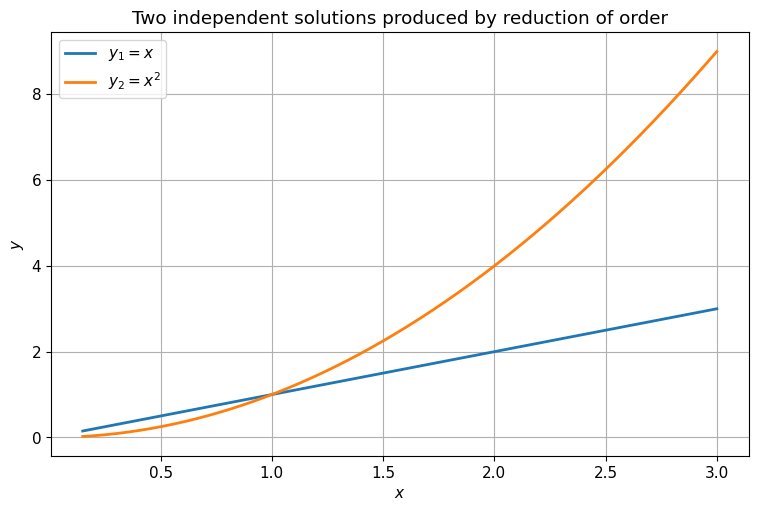

In [ ]:
x = np.linspace(.15, 3, 500)
y1 = x
y2 = x**2
plt.plot(x, y1, linewidth=2, label="$y_1=x$")
plt.plot(x, y2, linewidth=2, label="$y_2=x^2$")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.title("Two independent solutions produced by reduction of order")
plt.legend()
plt.show()

## 6. Interval Restrictions Matter

Consider

$$
y''+y=0
$$

with the known solution

$$
y_1=\cos x.
$$

Here

$$
P(x)=0.
$$

The formula gives

$$
y_2
=
\cos x
\int\frac{1}{\cos^2x}\,dx.
$$

Thus

$$
y_2
=
\cos x\int\sec^2x\,dx.
$$

Since

$$
\int\sec^2x\,dx=\tan x,
$$

we obtain

$$
y_2
=
\cos x\tan x
=
\sin x.
$$

The derivation must be performed on an interval avoiding zeros of $\cos x$ because the integrand contains $\sec^2x$. However, the simplified function

$$
\sin x
$$

is defined for all real $x$ and solves the differential equation globally.

This illustrates an important distinction:

- the **derivation interval** may be restricted;
- the **final solution formula** may extend farther after simplification.

## 7. What to Check After Using Reduction of Order

After constructing $y_2$, verify two facts:

1. $y_2$ satisfies the differential equation.
2. $y_1$ and $y_2$ are linearly independent.

A convenient independence check is

$$
W(y_1,y_2)\ne0.
$$

The method is not finished merely because an integral was evaluated.

## Classroom Checkpoint

In [ ]:
show_42_checkpoint()

### Classroom Checkpoint 1

<IPython.core.display.Math object>

Why must this formula be applied on an interval where $y_1$ does not vanish? Distinguish the interval required by the derivation from the possible domain of the final simplified $y_2$.

---

### Continue to the next section when ready.

## Section 4.3: Homogeneous Linear Equations with Constant Coefficients

## 1. Why Exponentials Are the Natural Trial Functions

Consider a homogeneous constant-coefficient equation

$$
a_ny^{(n)}+a_{n-1}y^{(n-1)}+\cdots+a_1y'+a_0y=0.
$$

We want a trial function whose derivatives preserve the same basic form.

The exponential function has exactly this property:

$$
y=e^{mx}
$$

gives

$$
y'=me^{mx},
$$

$$
y''=m^2e^{mx},
$$

and in general

$$
y^{(k)}=m^ke^{mx}.
$$

Thus every derivative is the original exponential multiplied by a power of $m$.

## 2. Constructing the Characteristic Equation

Substitute

$$
y=e^{mx}
$$

into

$$
a_ny^{(n)}+\cdots+a_1y'+a_0y=0.
$$

We obtain

$$
a_nm^ne^{mx}
+a_{n-1}m^{n-1}e^{mx}
+\cdots
+a_1me^{mx}
+a_0e^{mx}
=0.
$$

Factor out $e^{mx}$:

$$
e^{mx}
\left(
a_nm^n+a_{n-1}m^{n-1}+\cdots+a_1m+a_0
\right)
=0.
$$

Because

$$
e^{mx}\ne0,
$$

the polynomial factor must be zero:

$$
\boxed{
a_nm^n+a_{n-1}m^{n-1}+\cdots+a_1m+a_0=0.
}
$$

This polynomial equation is called the **characteristic equation** or **auxiliary equation**.

## 3. Second-Order Equations: Three Root Cases

For

$$
ay''+by'+cy=0,
$$

the characteristic equation is

$$
am^2+bm+c=0.
$$

Its roots determine the structure of the general solution.

### Case I: distinct real roots

If

$$
m_1\ne m_2
$$

are real, then

$$
\boxed{
y=c_1e^{m_1x}+c_2e^{m_2x}.
}
$$

### Case II: repeated real root

If

$$
m_1=m_2=m,
$$

then one exponential is not enough for a second-order equation. A second independent solution is

$$
xe^{mx}.
$$

Thus

$$
\boxed{
y=(c_1+c_2x)e^{mx}.
}
$$

### Case III: complex conjugate roots

If

$$
m=\alpha\pm i\beta,
\qquad\beta\ne0,
$$

then the real-valued general solution is

$$
\boxed{
y=e^{\alpha x}
\left(c_1\cos\beta x+c_2\sin\beta x\right).
}
$$

## 4. Why Complex Roots Produce Sines and Cosines

Euler's formula says

$$
e^{i\theta}=\cos\theta+i\sin\theta.
$$

If

$$
m=\alpha+i\beta,
$$

then

$$
e^{mx}
=e^{(\alpha+i\beta)x}
=e^{\alpha x}e^{i\beta x}.
$$

Using Euler's formula,

$$
e^{mx}
=e^{\alpha x}
\left(\cos\beta x+i\sin\beta x\right).
$$

Because the differential equation has real coefficients, the real and imaginary parts are themselves real solutions:

$$
e^{\alpha x}\cos\beta x,
\qquad
e^{\alpha x}\sin\beta x.
$$

The roles of the root components are therefore clear:

- $\alpha$ controls exponential growth or decay;
- $|\beta|$ controls oscillation frequency.

## 5. Detailed IVP Example with Complex Roots

Solve

$$
4y''+4y'+17y=0,
$$

subject to

$$
y(0)=-1,
\qquad
y'(0)=2.
$$

The characteristic equation is

$$
4m^2+4m+17=0.
$$

Using the quadratic formula,

$$
m
=
\frac{-4\pm\sqrt{16-272}}{8}.
$$

Thus

$$
m
=
\frac{-4\pm\sqrt{-256}}{8}
=
\frac{-4\pm16i}{8}.
$$

Therefore

$$
\boxed{m=-\frac12\pm2i.}
$$

The general solution is

$$
y=e^{-x/2}
\left(c_1\cos2x+c_2\sin2x\right).
$$

Apply

$$
y(0)=-1.
$$

Because

$$
e^0=1,
\quad
\cos0=1,
\quad
\sin0=0,
$$

we obtain

$$
c_1=-1.
$$

Now differentiate carefully. Write

$$
y=e^{-x/2}F(x),
$$

where

$$
F=c_1\cos2x+c_2\sin2x.
$$

Then

$$
y'
=e^{-x/2}
\left(F'-\frac12F\right).
$$

Also,

$$
F'=-2c_1\sin2x+2c_2\cos2x.
$$

At $x=0$,

$$
F(0)=c_1,
\qquad
F'(0)=2c_2.
$$

Thus

$$
y'(0)=2c_2-\frac12c_1.
$$

Use $y'(0)=2$ and $c_1=-1$:

$$
2=2c_2+\frac12.
$$

Therefore

$$
2c_2=\frac32,
$$

so

$$
c_2=\frac34.
$$

The IVP solution is

$$
\boxed{
y=e^{-x/2}
\left(-\cos2x+\frac34\sin2x\right).
}
$$

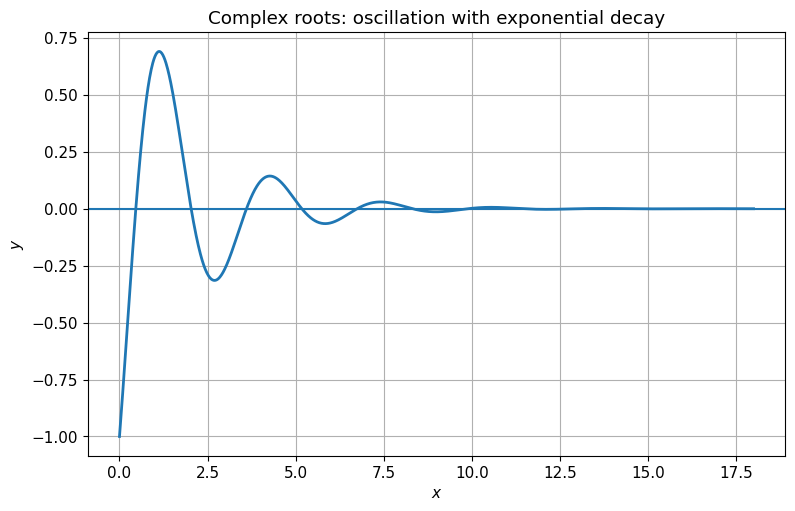

In [ ]:
x = np.linspace(0, 18, 1200)
y = np.exp(-x/2)*(-np.cos(2*x)+0.75*np.sin(2*x))
plt.plot(x, y, linewidth=2)
plt.axhline(0)
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.title("Complex roots: oscillation with exponential decay")
plt.show()

## 6. Repeated Roots of Higher Multiplicity

Suppose a real root $m=r$ has multiplicity $k$.

Then it contributes the $k$ independent solutions

$$
\boxed{
e^{rx},
\;xe^{rx},
\;x^2e^{rx},
\ldots,
x^{k-1}e^{rx}.
}
$$

If a complex pair

$$
\alpha\pm i\beta
$$

has multiplicity $k$, then both real oscillatory solutions are multiplied by

$$
1,x,\ldots,x^{k-1}.
$$

### Detailed higher-order example

Suppose the characteristic polynomial factors as

$$
(m+1)^2(m^2+4)^2.
$$

The root

$$
m=-1
$$

has multiplicity $2$, contributing

$$
e^{-x},
\qquad
xe^{-x}.
$$

The roots

$$
m=\pm2i
$$

form a complex pair of multiplicity $2$, contributing

$$
\cos2x,
\quad
\sin2x,
\quad
x\cos2x,
\quad
x\sin2x.
$$

Thus the sixth-order general solution is

$$
\boxed{
y=(c_1+c_2x)e^{-x}
+(c_3+c_4x)\cos2x
+(c_5+c_6x)\sin2x.
}
$$

There are six arbitrary constants, matching the order of the differential equation.

## 7. Factoring Higher-Degree Characteristic Polynomials

For a cubic or quartic characteristic polynomial with integer coefficients, useful tools include

- common-factor extraction;
- grouping;
- known factor patterns;
- the rational-root theorem.

For

$$
a_nm^n+\cdots+a_0,
$$

a rational root $p/q$ in lowest terms must satisfy

$$
p\mid a_0,
\qquad
q\mid a_n.
$$

Once one root is found, divide the polynomial by the corresponding linear factor and continue factoring.

In [ ]:
def root_behavior(case="distinct"):
    x = np.linspace(0, 8, 700)
    if case == "distinct":
        y = np.exp(-x) - .5*np.exp(-3*x)
        title = "Distinct negative real roots: two decay rates"
    elif case == "repeated":
        y = (1+x)*np.exp(-x)
        title = "Repeated negative root: polynomial times exponential"
    elif case == "complex_decay":
        y = np.exp(-.4*x)*np.cos(2*x)
        title = "Complex roots with negative real part: damped oscillation"
    else:
        y = np.exp(.25*x)*np.cos(2*x)
        title = "Complex roots with positive real part: growing oscillation"
    plt.plot(x,y,linewidth=2)
    plt.axhline(0)
    plt.xlabel("$x$")
    plt.ylabel("$y$")
    plt.title(title)
    plt.show()

interact(
    root_behavior,
    case=Dropdown(options=[
        ("distinct real", "distinct"),
        ("repeated real", "repeated"),
        ("complex decay", "complex_decay"),
        ("complex growth", "complex_growth")
    ], value="distinct", description="roots")
);

interactive(children=(Dropdown(description='roots', options=(('distinct real', 'distinct'), ('repeated real', …

## Classroom Checkpoint

In [ ]:
show_43_checkpoint()

### Classroom Checkpoint 1

<IPython.core.display.Math object>

Write the real-valued general solution corresponding to these characteristic roots. Explain which factor comes from multiplicity and which factor comes from the complex roots.

---

### Continue to the next section when ready.

## Section 4.4: Undetermined Coefficients — Superposition Approach

## 1. The Structure of a Nonhomogeneous Linear Solution

For a nonhomogeneous constant-coefficient equation

$$
L[y]=g(x),
$$

Section 4.1 showed that the general solution has the form

$$
\boxed{y=y_c+y_p.}
$$

Here

- $y_c$ is the general solution of the associated homogeneous equation $L[y]=0$;
- $y_p$ is one particular solution satisfying $L[y_p]=g(x)$.

The method of **undetermined coefficients** is a systematic way to guess the *form* of $y_p$ and then determine the unknown coefficients by substitution.

## 2. When the Method Applies

Undetermined coefficients is especially efficient when

1. the differential equation has **constant coefficients**, and
2. the forcing $g(x)$ is built from a finite combination of

$$
\text{polynomials},\qquad e^{ax},\qquad \cos bx,\qquad \sin bx,
$$

and products of these functions.

Why these families?

Because differentiating them repeatedly never produces fundamentally new types of functions. They form a finite-dimensional **derivative-closed family**.

For example, differentiating

$$
e^{ax}\cos bx
$$

produces a combination of

$$
e^{ax}\cos bx
\quad\text{and}\quad
e^{ax}\sin bx.
$$

Therefore both functions must be included in a trial even if only one appears in the forcing.

## 3. Building the Trial Function

A useful reference is

$$
\renewcommand{\arraystretch}{1.7}
\begin{array}{|c|c|}
\hline
\textbf{Forcing }g(x) & \textbf{Initial trial for }y_p \\
\hline
P_n(x) & A_nx^n+\cdots+A_1x+A_0 \\
\hline
e^{ax}P_n(x) & e^{ax}(A_nx^n+\cdots+A_0) \\
\hline
P_n(x)\cos bx & P_n^*(x)\cos bx+Q_n^*(x)\sin bx \\
\hline
P_n(x)\sin bx & P_n^*(x)\cos bx+Q_n^*(x)\sin bx \\
\hline
e^{ax}P_n(x)\cos bx & e^{ax}[P_n^*(x)\cos bx+Q_n^*(x)\sin bx] \\
\hline
\end{array}
$$

The starred polynomials contain independent unknown coefficients.

After choosing the family, we must perform one more check:

> Does any part of the trial already belong to the complementary solution $y_c$?

## 4. Detailed Polynomial Example

Solve

$$
y''-y=3x^2-2x+5.
$$

### Step 1: complementary solution

The homogeneous equation is

$$
y''-y=0.
$$

Its characteristic equation is

$$
m^2-1=0,
$$

so

$$
m=\pm1.
$$

Therefore

$$
\boxed{y_c=c_1e^x+c_2e^{-x}.}
$$

### Step 2: choose a particular trial

The forcing is a quadratic polynomial. Therefore try

$$
y_p=Ax^2+Bx+C.
$$

Differentiate:

$$
y_p'=2Ax+B,
$$

$$
y_p''=2A.
$$

Substitute into

$$
y''-y=3x^2-2x+5:
$$

$$
2A-(Ax^2+Bx+C)=3x^2-2x+5.
$$

Rearrange the left side by powers of $x$:

$$
-Ax^2-Bx+(2A-C)=3x^2-2x+5.
$$

Since the two polynomials are equal for every $x$, corresponding coefficients must match:

$$
-A=3,
$$

$$
-B=-2,
$$

$$
2A-C=5.
$$

Thus

$$
A=-3,
\qquad
B=2.
$$

Use $A=-3$ in the constant equation:

$$
2(-3)-C=5,
$$

so

$$
-6-C=5,
$$

and

$$
C=-11.
$$

Therefore

$$
\boxed{y_p=-3x^2+2x-11.}
$$

The general solution is

$$
\boxed{y=c_1e^x+c_2e^{-x}-3x^2+2x-11.}
$$

## 5. Superposition for Mixed Forcing

Consider

$$
y''+y=x+2e^{2x}+3\cos4x.
$$

The forcing is a sum of three different families:

$$
g_1=x,
\qquad
g_2=2e^{2x},
\qquad
g_3=3\cos4x.
$$

Because the differential operator is linear, we may seek

$$
y_p=y_{p1}+y_{p2}+y_{p3},
$$

where each component responds to one forcing term.

The complementary equation

$$
y''+y=0
$$

has

$$
y_c=c_1\cos x+c_2\sin x.
$$

For $g_1=x$, try

$$
y_{p1}=Ax+B.
$$

Because $y_{p1}''=0$,

$$
Ax+B=x,
$$

so

$$
A=1,
\qquad B=0,
$$

and

$$
y_{p1}=x.
$$

For $g_2=2e^{2x}$, try

$$
y_{p2}=Ce^{2x}.
$$

Then

$$
y_{p2}''+y_{p2}=4Ce^{2x}+Ce^{2x}=5Ce^{2x}.
$$

Therefore

$$
5C=2,
$$

so

$$
y_{p2}=\frac25e^{2x}.
$$

For $g_3=3\cos4x$, try

$$
y_{p3}=D\cos4x+E\sin4x.
$$

Differentiate twice:

$$
y_{p3}''=-16D\cos4x-16E\sin4x.
$$

Therefore

$$
y_{p3}''+y_{p3}
=-15D\cos4x-15E\sin4x.
$$

Match with

$$
3\cos4x+0\sin4x.
$$

Thus

$$
-15D=3,
\qquad
-15E=0.
$$

Hence

$$
D=-\frac15,
\qquad E=0.
$$

So

$$
y_{p3}=-\frac15\cos4x.
$$

Combining the three particular responses,

$$
\boxed{
y_p=x+\frac25e^{2x}-\frac15\cos4x.
}
$$

Therefore

$$
\boxed{
y=c_1\cos x+c_2\sin x+x+\frac25e^{2x}-\frac15\cos4x.
}
$$

## 6. Duplication and Resonance

Now consider

$$
y''+4y=\cos2x.
$$

The homogeneous characteristic equation is

$$
m^2+4=0,
$$

so

$$
y_c=c_1\cos2x+c_2\sin2x.
$$

The usual trigonometric trial

$$
A\cos2x+B\sin2x
$$

is already contained in $y_c$.

If we substitute such a trial, the left side becomes zero because every member of that family solves the homogeneous equation. Therefore the trial can never produce the nonzero forcing $\cos2x$.

This is the algebraic meaning of **resonance** in the method of undetermined coefficients.

### The multiplication rule

To create a linearly independent trial, multiply the entire duplicated trial by $x$:

$$
y_p=x(A\cos2x+B\sin2x).
$$

Substitution gives

$$
y_p''+4y_p
=-4A\sin2x+4B\cos2x.
$$

Match with

$$
\cos2x.
$$

Thus

$$
-4A=0,
\qquad
4B=1.
$$

Therefore

$$
A=0,
\qquad
B=\frac14.
$$

A particular solution is

$$
\boxed{y_p=\frac{x}{4}\sin2x.}
$$

The factor $x$ produces the linearly growing oscillatory envelope associated with exact resonance.

In [ ]:
def forced_oscillator(omega=1.8, omega0=2.0, T=40):
    if abs(omega-omega0) < 1e-6:
        t=np.linspace(0,T,1200)
        y=t*np.sin(omega0*t)/(2*omega0)
        label='exact resonance'
    else:
        t=np.linspace(0,T,1200)
        y=(np.cos(omega*t)-np.cos(omega0*t))/(omega0**2-omega**2)
        label='nonresonant response'
    plt.plot(t,y,linewidth=2)
    plt.xlabel('$t$'); plt.ylabel('$y(t)$')
    plt.title(label+f': $\\omega={omega:.2f}$, $\\omega_0={omega0:.2f}$')
    plt.show()

interact(
    forced_oscillator,
    omega=FloatSlider(min=1.0,max=3.0,step=.1,value=1.8,description='$\\omega$'),
    omega0=FloatSlider(min=1.0,max=3.0,step=.1,value=2.0,description='$\\omega_0$'),
    T=IntSlider(min=10,max=60,step=10,value=40,description='time')
);

interactive(children=(FloatSlider(value=1.8, description='$\\omega$', max=3.0, min=1.0), FloatSlider(value=2.0…

## 7. General Resonance Rule

Suppose the forcing-based trial overlaps the complementary solution.

Multiply the **entire overlapping trial component** by

$$
x^s,
$$

where $s$ is the smallest positive integer that removes the duplication.

Equivalently, $s$ is the multiplicity with which the relevant forcing root already occurs in the characteristic polynomial.

This root-multiplicity interpretation will become even clearer in the annihilator approach of Section 4.5.

## Classroom Checkpoint

In [ ]:
show_44_checkpoint()

### Classroom Checkpoint 1

<IPython.core.display.Math object>

Choose the correct undetermined-coefficients trial. Be sure to check for duplication with the complementary solution before finalizing the trial.

---

### Continue to the next section when ready.

## Section 4.5: Undetermined Coefficients — Annihilator Approach

## 1. Differential Operators Revisited

Let

$$
D=\frac{d}{dx}.
$$

Then a constant-coefficient differential equation can be written as a polynomial in $D$:

$$
L(D)y=g(x).
$$

For example,

$$
y''+3y'+2y=g(x)
$$

becomes

$$
\boxed{(D^2+3D+2)y=g(x).}
$$

The operator factors just like an algebraic polynomial:

$$
D^2+3D+2=(D+1)(D+2).
$$

Because constant-coefficient differential operators commute,

$$
(D+1)(D+2)y=(D+2)(D+1)y.
$$

## 2. What Is an Annihilator?

A differential operator $A(D)$ is called an **annihilator** of a function $f$ if

$$
\boxed{A(D)f=0.}
$$

The idea is simple: apply a differential operator enough times, or in the right shifted combination, so that the forcing function disappears.

Examples:

$$
D(1)=0,
$$

so $D$ annihilates constants.

Also,

$$
D^2(x)=0,
$$

so $D^2$ annihilates every linear polynomial.

More generally,

$$
\boxed{D^{n+1}}
$$

annihilates every polynomial of degree at most $n$.

### Exponential functions

For

$$
f=e^{ax},
$$

we have

$$
Df=ae^{ax}.
$$

Therefore

$$
(D-a)e^{ax}=0.
$$

Thus

$$
\boxed{D-a}
$$

annihilates $e^{ax}$.

If a polynomial factor is present,

$$
x^ne^{ax},
$$

then

$$
\boxed{(D-a)^{n+1}}
$$

annihilates the entire family $e^{ax}P_n(x)$.

### Sines and cosines

For

$$
f=\cos bx,
$$

we have

$$
f''=-b^2\cos bx.
$$

Thus

$$
f''+b^2f=0.
$$

Therefore

$$
\boxed{D^2+b^2}
$$

annihilates both

$$
\cos bx
\quad\text{and}\quad
\sin bx.
$$

Combining exponential and trigonometric behavior gives the shifted operator

$$
\boxed{(D-a)^2+b^2}
$$

for $e^{ax}\cos bx$ and $e^{ax}\sin bx$.

## 3. Why the Annihilator Method Produces the Same Trial Families

Suppose

$$
L(D)y=g(x).
$$

Choose $A(D)$ so that

$$
A(D)g=0.
$$

Apply $A(D)$ to both sides:

$$
A(D)L(D)y=A(D)g=0.
$$

Therefore every solution of the original nonhomogeneous equation must also satisfy the higher-order homogeneous equation

$$
\boxed{A(D)L(D)y=0.}
$$

The solution space of this enlarged homogeneous equation contains

1. the complementary solutions coming from $L(D)$, and
2. additional solutions introduced by the roots of $A(D)$.

Those **additional solutions** tell us the trial form for $y_p$.

## 4. Detailed Example

Solve

$$
y''+3y'+2y=4x^2.
$$

The left operator is

$$
L(D)=D^2+3D+2=(D+1)(D+2).
$$

Therefore the complementary solution is

$$
\boxed{y_c=c_1e^{-x}+c_2e^{-2x}.}
$$

The forcing $4x^2$ is a quadratic polynomial. A quadratic polynomial is annihilated by

$$
D^3.
$$

Apply $D^3$ to both sides:

$$
D^3(D+1)(D+2)y=0.
$$

The roots of the enlarged characteristic equation are

$$
-1,-2,0,0,0.
$$

Thus the enlarged homogeneous solution contains

$$
e^{-x},\quad e^{-2x},\quad 1,\quad x,\quad x^2.
$$

The first two terms already belong to $y_c$. Remove them when constructing the particular trial.

Therefore choose

$$
\boxed{y_p=A+Bx+Cx^2.}
$$

This is exactly the same trial that the superposition form of undetermined coefficients would have produced.

Now determine the coefficients.

$$
y_p=A+Bx+Cx^2,
$$

$$
y_p'=B+2Cx,
$$

$$
y_p''=2C.
$$

Substitute into

$$
y''+3y'+2y=4x^2:
$$

$$
2C+3(B+2Cx)+2(A+Bx+Cx^2)=4x^2.
$$

Collect powers:

$$
2Cx^2+(6C+2B)x+(2C+3B+2A)=4x^2.
$$

Match coefficients:

$$
2C=4,
$$

$$
6C+2B=0,
$$

$$
2C+3B+2A=0.
$$

From the first equation,

$$
C=2.
$$

Then

$$
12+2B=0,
$$

so

$$
B=-6.
$$

Finally,

$$
4-18+2A=0,
$$

so

$$
2A=14,
$$

and

$$
A=7.
$$

Thus

$$
\boxed{y_p=7-6x+2x^2.}
$$

The general solution is

$$
\boxed{y=c_1e^{-x}+c_2e^{-2x}+7-6x+2x^2.}
$$

## 5. Root Multiplicity Explains Resonance

Consider

$$
(D^2+4)y=\cos2x.
$$

The forcing $\cos2x$ is annihilated by

$$
D^2+4.
$$

Applying the annihilator gives

$$
(D^2+4)^2y=0.
$$

The roots $\pm2i$ now have multiplicity $2$.

The first copy produces the complementary functions

$$
\cos2x,
\qquad
\sin2x.
$$

The second copy produces the new functions

$$
x\cos2x,
\qquad
x\sin2x.
$$

Therefore the particular trial must use

$$
\boxed{x(A\cos2x+B\sin2x).}
$$

So the multiplication-by-$x$ rule from Section 4.4 is not arbitrary; it is a direct consequence of repeated characteristic roots.

## 6. A More Complicated Forcing Family

Consider

$$
g(x)=x^2e^x\cos3x.
$$

The basic exponential-trigonometric family corresponds to the complex roots

$$
1\pm3i.
$$

The operator is

$$
(D-1)^2+9.
$$

Because the polynomial factor has degree $2$, the operator must have multiplicity $3$:

$$
\boxed{
A(D)=\left[(D-1)^2+9\right]^3.
}
$$

The corresponding trial family contains

$$
e^xP_2(x)\cos3x
$$

and

$$
e^xQ_2(x)\sin3x.
$$

Explicitly,

$$
\boxed{
y_p=e^x[(Ax^2+Bx+C)\cos3x+(Dx^2+Ex+F)\sin3x],
}
$$

unless additional duplication with $y_c$ requires another power of $x$.

In [ ]:
def annihilator_picture(kind='polynomial'):
    x=np.linspace(-2,2,600)
    if kind=='polynomial':
        f=x**3-2*x
        title=r'$x^3-2x$ is annihilated by $D^4$'
    elif kind=='exponential':
        f=np.exp(x)
        title=r'$e^x$ is annihilated by $D-1$'
    else:
        f=np.exp(-.4*x)*np.cos(3*x)
        title=r'$e^{-0.4x}\cos3x$ has a shifted trigonometric annihilator'
    plt.plot(x,f,linewidth=2)
    plt.xlabel('$x$'); plt.ylabel('$f(x)$'); plt.title(title); plt.show()

interact(annihilator_picture,kind=Dropdown(options=['polynomial','exponential','exp-trig'],value='polynomial',description='family'));

interactive(children=(Dropdown(description='family', options=('polynomial', 'exponential', 'exp-trig'), value=…

## Classroom Checkpoint

In [ ]:
show_45_checkpoint()

### Classroom Checkpoint 1

<IPython.core.display.Math object>

Give a minimal constant-coefficient annihilator for this forcing function and explain the role of the exponential shift, trigonometric frequency, and polynomial degree.

---

### Continue to the next section when ready.

## Section 4.6: Variation of Parameters

## 1. Why We Need Another Method

Undetermined coefficients is efficient, but it is restricted to special forcing families and constant-coefficient equations.

What if the forcing is

$$
\frac{1}{1+x^2},
$$

$$
\ln x,
$$

or another function outside the usual polynomial-exponential-trigonometric catalog?

The method of **variation of parameters** is much more general.

Its central idea is to start with the complementary solution

$$
y_c=c_1y_1+c_2y_2
$$

and replace the constants by functions:

$$
\boxed{y_p=u_1(x)y_1(x)+u_2(x)y_2(x).}
$$

## 2. Standard Form Comes First

Variation of parameters is derived for the normalized equation

$$
\boxed{y''+P(x)y'+Q(x)y=f(x).}
$$

If the original equation is

$$
a(x)y''+b(x)y'+c(x)y=g(x),
$$

divide by $a(x)$ first:

$$
y''+\frac{b(x)}{a(x)}y'+\frac{c(x)}{a(x)}y=\frac{g(x)}{a(x)}.
$$

Therefore the forcing used in the formulas is

$$
f(x)=\frac{g(x)}{a(x)},
$$

not the unnormalized right-hand side.

## 3. Deriving the Method Step by Step

Let $y_1,y_2$ be a fundamental set for

$$
y''+Py'+Qy=0.
$$

Seek

$$
y_p=u_1y_1+u_2y_2.
$$

Differentiate:

$$
y_p'
=u_1'y_1+u_1y_1'+u_2'y_2+u_2y_2'.
$$

At this point there are two unknown functions, $u_1$ and $u_2$, but only one differential equation. We have freedom to impose one additional condition that simplifies the algebra.

Choose

$$
\boxed{u_1'y_1+u_2'y_2=0.}
$$

Then

$$
\boxed{y_p'=u_1y_1'+u_2y_2'.}
$$

Differentiate again:

$$
y_p''
=u_1'y_1'+u_1y_1''+u_2'y_2'+u_2y_2''.
$$

Substitute $y_p,y_p',y_p''$ into

$$
y''+Py'+Qy=f.
$$

We obtain

$$
u_1'y_1'+u_2'y_2'
+u_1(y_1''+Py_1'+Qy_1)
+u_2(y_2''+Py_2'+Qy_2)
=f.
$$

But $y_1$ and $y_2$ solve the homogeneous equation, so

$$
y_1''+Py_1'+Qy_1=0,
$$

and

$$
y_2''+Py_2'+Qy_2=0.
$$

Thus the terms involving $u_1$ and $u_2$ disappear, leaving

$$
\boxed{u_1'y_1'+u_2'y_2'=f.}
$$

We now have a $2\times2$ linear system for $u_1'$ and $u_2'$:

$$
\boxed{
\begin{aligned}
y_1u_1'+y_2u_2'&=0,\\
y_1'u_1'+y_2'u_2'&=f.
\end{aligned}
}
$$

The determinant of the coefficient matrix is the Wronskian

$$
W=y_1y_2'-y_1'y_2.
$$

Because $y_1,y_2$ form a fundamental set,

$$
W\ne0.
$$

Cramer's rule gives

$$
\boxed{u_1'=-\frac{y_2f}{W},}
$$

and

$$
\boxed{u_2'=\frac{y_1f}{W}.}
$$

Then integrate $u_1'$ and $u_2'$ and form

$$
y_p=u_1y_1+u_2y_2.
$$

### Why constants of integration can be omitted

Suppose integrating $u_1'$ gives

$$
u_1=U_1+C_1.
$$

Then the contribution to $y_p$ is

$$
(U_1+C_1)y_1=U_1y_1+C_1y_1.
$$

But $C_1y_1$ is already part of the complementary solution.

The same is true for the constant in $u_2$.

Therefore, when constructing one particular solution, we normally omit those constants.

## 4. Detailed Example: $y''+y=e^x$

The associated homogeneous equation is

$$
y''+y=0.
$$

Choose

$$
y_1=\cos x,
\qquad
y_2=\sin x.
$$

Then

$$
y_1'=-\sin x,
\qquad
y_2'=\cos x.
$$

The Wronskian is

$$
W
=
\cos x(\cos x)-(-\sin x)(\sin x).
$$

Thus

$$
W=\cos^2x+\sin^2x=1.
$$

The forcing is

$$
f=e^x.
$$

Therefore

$$
u_1'
=-\frac{y_2f}{W}
=-e^x\sin x,
$$

and

$$
u_2'
=\frac{y_1f}{W}
=e^x\cos x.
$$

Use the standard integration formulas

$$
\int e^x\sin x\,dx
=\frac{e^x}{2}(\sin x-\cos x),
$$

and

$$
\int e^x\cos x\,dx
=\frac{e^x}{2}(\sin x+\cos x).
$$

Hence

$$
u_1
=-\frac{e^x}{2}(\sin x-\cos x)
=\frac{e^x}{2}(\cos x-\sin x),
$$

and

$$
u_2
=\frac{e^x}{2}(\sin x+\cos x).
$$

Now

$$
y_p=u_1\cos x+u_2\sin x.
$$

Substitute:

$$
y_p
=
\frac{e^x}{2}(\cos x-\sin x)\cos x
+
\frac{e^x}{2}(\sin x+\cos x)\sin x.
$$

Factor $e^x/2$:

$$
y_p
=
\frac{e^x}{2}
[\cos^2x-\sin x\cos x+\sin^2x+\sin x\cos x].
$$

The mixed terms cancel and

$$
\cos^2x+\sin^2x=1.
$$

Therefore

$$
\boxed{y_p=\frac12e^x.}
$$

The general solution is

$$
\boxed{y=c_1\cos x+c_2\sin x+\frac12e^x.}
$$

## 5. Integral-Defined Particular Solutions Are Still Exact

Consider

$$
y''+y=\frac{1}{1+x^2},
$$

with zero initial data

$$
y(0)=0,
\qquad y'(0)=0.
$$

Using the same fundamental pair $\cos x,\sin x$, a convenient definite-integral form is

$$
\boxed{
y(x)
=
\int_0^x
\sin(x-t)\frac{1}{1+t^2}\,dt.
}
$$

The integral need not simplify to elementary functions for the representation to be exact.

This is an important conceptual shift: a closed elementary formula is not required for a mathematically complete solution.

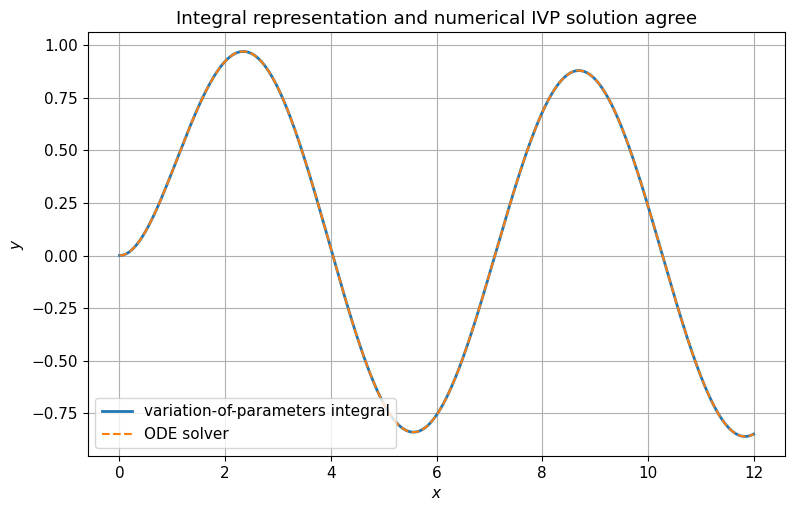

In [ ]:
def vop_integral_demo(T=12):
    x=np.linspace(0,T,900)
    y=np.zeros_like(x)
    for j,xx in enumerate(x):
        t=x[:j+1]
        integrand=np.sin(xx-t)/(1+t**2)
        y[j]=np.trapezoid(integrand,t) if len(t)>1 else 0

    def rhs(t,z):
        return [z[1],1/(1+t*t)-z[0]]
    sol=solve_ivp(rhs,(0,T),[0,0],t_eval=x,rtol=1e-9,atol=1e-11)

    plt.plot(x,y,linewidth=2,label='variation-of-parameters integral')
    plt.plot(x,sol.y[0],'--',linewidth=1.5,label='ODE solver')
    plt.xlabel('$x$'); plt.ylabel('$y$')
    plt.title('Integral representation and numerical IVP solution agree')
    plt.legend(); plt.show()

vop_integral_demo()

## 6. Choosing Between the Two Nonhomogeneous Methods

$$
\renewcommand{\arraystretch}{1.6}
\begin{array}{|c|c|c|}
\hline
& \textbf{Undetermined coefficients} & \textbf{Variation of parameters}\\
\hline
\text{Coefficient requirement} & \text{constant coefficients} & \text{variable coefficients allowed}\\
\hline
\text{Forcing requirement} & \text{special derivative-closed families} & \text{broadly applicable}\\
\hline
\text{Main work} & \text{choose trial and match coefficients} & \text{compute }W,u_1',u_2'\text{ and integrate}\\
\hline
\text{Typical advantage} & \text{fast when applicable} & \text{general}\\
\hline
\end{array}
$$

The methods are not competitors in the sense that one is always better. The structure of the equation determines which method is most efficient.

## Classroom Checkpoint

In [ ]:
show_46_checkpoint()

### Classroom Checkpoint 1

<IPython.core.display.Math object>

Compute the Wronskian and then derive $u_1'$ and $u_2'$ from the variation-of-parameters formulas.

---

### Continue to the next section when ready.

## Section 4.7: Cauchy–Euler Equations

## 1. Recognizing a Cauchy--Euler Equation

A second-order **Cauchy--Euler equation** has the form

$$
\boxed{ax^2y''+bxy'+cy=g(x),}
$$

where $a,b,c$ are constants.

The coefficient attached to each derivative compensates for the power lost by differentiation:

- $y''$ is multiplied by $x^2$;
- $y'$ is multiplied by $x$;
- $y$ is multiplied by a constant.

For the homogeneous equation,

$$
ax^2y''+bxy'+cy=0,
$$

this scaling structure suggests a power trial rather than an exponential trial.

## 2. Why Try $y=x^m$?

For constant-coefficient equations, $e^{mx}$ works because differentiating preserves the exponential form.

For a Cauchy--Euler equation, powers have an analogous property after the variable coefficients are included.

Let

$$
y=x^m.
$$

Then

$$
y'=mx^{m-1},
$$

and

$$
y''=m(m-1)x^{m-2}.
$$

Multiplying by the Cauchy--Euler coefficients gives

$$
x^2y''=m(m-1)x^m,
$$

and

$$
xy'=mx^m.
$$

Every term is now proportional to $x^m$.

## 3. Constructing the Indicial Equation

Substitute $y=x^m$ into

$$
ax^2y''+bxy'+cy=0.
$$

We obtain

$$
a m(m-1)x^m+bmx^m+cx^m=0.
$$

Factor $x^m$:

$$
x^m\left[a m(m-1)+bm+c\right]=0.
$$

On an interval where $x\ne0$, the power factor is not the source of the equation. Therefore

$$
\boxed{a m(m-1)+bm+c=0.}
$$

This is the **indicial equation** or auxiliary equation for the Cauchy--Euler equation.

## 4. The Singular Point $x=0$

The point

$$
\boxed{x=0}
$$

is special because the leading coefficient $ax^2$ vanishes there.

After dividing by $ax^2$, the equation contains terms such as

$$
\frac1x
\quad\text{and}\quad
\frac1{x^2},
$$

which are undefined at $x=0$.

Therefore solutions are naturally studied on intervals that do not cross zero, such as

$$
(0,\infty)
$$

or

$$
(-\infty,0).
$$

The standard formulas involving $\ln x$ are written most naturally on $x>0$.

## 5. Case I: Distinct Real Roots

Suppose the indicial equation has distinct real roots

$$
m_1\ne m_2.
$$

Then

$$
\boxed{y=c_1x^{m_1}+c_2x^{m_2}.}
$$

### Detailed example

Solve

$$
x^2y''-4xy'+4y=0,
\qquad x>0.
$$

The indicial equation is

$$
m(m-1)-4m+4=0.
$$

Expand:

$$
m^2-m-4m+4=0,
$$

so

$$
m^2-5m+4=0.
$$

Factor:

$$
(m-1)(m-4)=0.
$$

Therefore

$$
m_1=1,
\qquad
m_2=4.
$$

Hence

$$
\boxed{y=c_1x+c_2x^4.}
$$

## 6. Case II: Repeated Real Root

If the indicial equation has a repeated root

$$
m=r,
$$

one solution is

$$
x^r.
$$

The second independent solution is

$$
x^r\ln x.
$$

Thus

$$
\boxed{y=x^r(c_1+c_2\ln x),\qquad x>0.}
$$

The logarithm plays the same role that the factor $x$ played for repeated roots in constant-coefficient equations.

### Detailed repeated-root example

Solve

$$
x^2y''-3xy'+4y=0.
$$

The indicial equation is

$$
m(m-1)-3m+4=0.
$$

Expand:

$$
m^2-m-3m+4=0,
$$

so

$$
m^2-4m+4=0.
$$

Factor:

$$
(m-2)^2=0.
$$

Therefore

$$
m=2
$$

is repeated, and

$$
\boxed{y=x^2(c_1+c_2\ln x),\qquad x>0.}
$$

## 7. Case III: Complex Roots

Suppose

$$
m=\alpha\pm i\beta.
$$

The corresponding complex power is

$$
x^{\alpha+i\beta}.
$$

For $x>0$,

$$
x^{\alpha+i\beta}
=e^{(\alpha+i\beta)\ln x}.
$$

Separate the real and imaginary parts:

$$
=e^{\alpha\ln x}e^{i\beta\ln x}.
$$

Since

$$
e^{\alpha\ln x}=x^\alpha,
$$

and Euler's formula gives

$$
e^{i\beta\ln x}
=\cos(\beta\ln x)+i\sin(\beta\ln x),
$$

we obtain the real solution family

$$
\boxed{
y=x^\alpha
\left[c_1\cos(\beta\ln x)+c_2\sin(\beta\ln x)\right].
}
$$

### Logarithmic oscillation

The oscillation occurs in

$$
\ln x,
$$

not directly in $x$.

For example,

$$
y=\cos(2\ln x)
$$

has zeros when

$$
2\ln x=\frac\pi2+k\pi.
$$

Therefore

$$
x=
\exp\left(\frac\pi4+\frac{k\pi}{2}\right).
$$

Successive zeros are related multiplicatively rather than additively. On an ordinary $x$-axis, the oscillations stretch farther apart as $x$ increases.

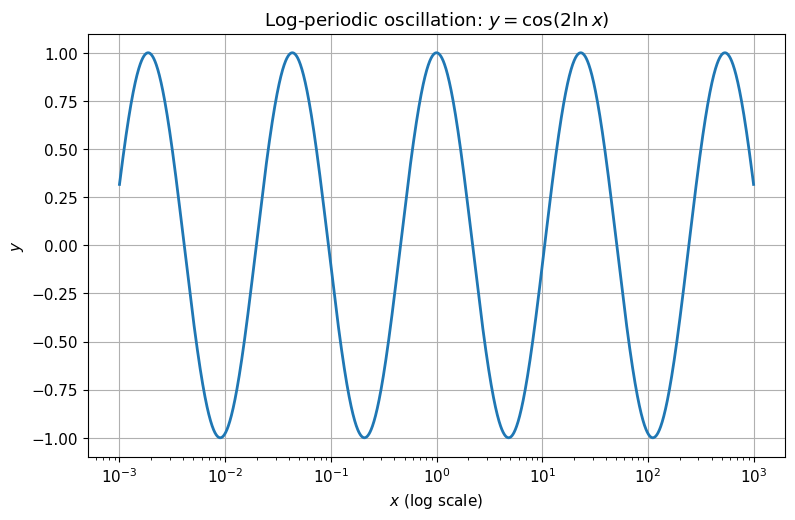

In [ ]:
x=np.logspace(-3,3,2500)
y=np.cos(2*np.log(x))
plt.semilogx(x,y,linewidth=2)
plt.xlabel('$x$ (log scale)'); plt.ylabel('$y$')
plt.title(r'Log-periodic oscillation: $y=\cos(2\ln x)$')
plt.show()

## 8. Transforming to a Constant-Coefficient Equation

The substitution

$$
\boxed{t=\ln x}
$$

reveals a deep connection between Cauchy--Euler and constant-coefficient equations.

Let

$$
Y(t)=y(e^t).
$$

Because

$$
x=e^t,
$$

we have

$$
\frac{dt}{dx}=\frac1x.
$$

By the chain rule,

$$
y'=
\frac{dY}{dt}\frac{dt}{dx}
=
\frac1xY_t.
$$

Therefore

$$
\boxed{xy'=Y_t.}
$$

Differentiate again:

$$
y'=rac{Y_t}{x}.
$$

Using the product rule,

$$
y''
=
\frac{d}{dx}(x^{-1}Y_t).
$$

Thus

$$
y''
=
-x^{-2}Y_t
+x^{-1}\frac{dY_t}{dx}.
$$

Again by the chain rule,

$$
\frac{dY_t}{dx}
=Y_{tt}\frac{dt}{dx}
=\frac{Y_{tt}}{x}.
$$

Therefore

$$
y''
=
\frac{Y_{tt}-Y_t}{x^2}.
$$

Hence

$$
\boxed{x^2y''=Y_{tt}-Y_t.}
$$

Substituting into

$$
ax^2y''+bxy'+cy=0
$$

gives

$$
a(Y_{tt}-Y_t)+bY_t+cY=0,
$$

or

$$
\boxed{aY_{tt}+(b-a)Y_t+cY=0.}
$$

This is a constant-coefficient equation in the variable $t$.

## Classroom Checkpoint

In [ ]:
show_47_checkpoint()

### Classroom Checkpoint 1

<IPython.core.display.Math object>

Solve the Cauchy--Euler equation. Show the indicial equation and explain why complex powers become trigonometric functions of $\ln x$.

---

### Continue to the next section when ready.

## Section 4.8: Green's Functions


## 1. From a Forcing Function to a Response Kernel

Consider the nonhomogeneous linear second-order differential equation

$$
\boxed{
y''+P(x)y'+Q(x)y=f(x).
}
$$

We can write this more compactly as

$$
\boxed{
L[y]=f(x),
}
$$

where

$$
L[y]
=
y''+P(x)y'+Q(x)y
$$

is a **linear differential operator**.

The function

$$
f(x)
$$

is called the **forcing function**, because it represents an external input acting on the system.

For example:

- in a mechanical system, $f(x)$ may represent an applied force;
- in an electrical circuit, it may represent an external voltage or current;
- in a population model, it may represent an external input into the population;
- in a heat problem, it may represent a heat source.

The important point is that the differential equation tells us how the system **responds** to this forcing.

---

### 1.1 Why Does Linearity Matter?

Because $L$ is linear,

$$
L[c_1y_1+c_2y_2]
=
c_1L[y_1]+c_2L[y_2].
$$

This gives us the **superposition principle**.

Suppose one forcing function $f_1(x)$ produces a response $y_1(x)$:

$$
L[y_1]=f_1,
$$

and another forcing function $f_2(x)$ produces a response $y_2(x)$:

$$
L[y_2]=f_2.
$$

Then

$$
L[y_1+y_2]
=
f_1+f_2.
$$

Therefore, if the total forcing is the sum of several smaller forcing inputs, the total response is the sum of the responses produced by those inputs.

Symbolically,

$$
\boxed{
\text{sum of inputs}
\quad\Longrightarrow\quad
\text{sum of responses}.
}
$$

This observation is the basic idea behind a Green's function.

---

### 1.2 Think of the Forcing as Many Small Inputs

Instead of thinking of $f(x)$ as one large forcing function, imagine breaking it into many very small pieces.

For example, divide the interval from $x_0$ to $x$ into small pieces:

$$
x_0=t_0<t_1<t_2<\cdots<t_n=x.
$$

Near a point $t_i$, the forcing contributes approximately

$$
f(t_i)\,\Delta t.
$$

We may think of this as a small input applied near the location

$$
t=t_i.
$$

Because the system is linear, we can:

1. find the response caused by each small input;
2. add all of those responses together.

Schematically,

$$
\text{total response}
\approx
\sum_i
\left(
\text{response to input at }t_i
\right).
$$

As the pieces become smaller and smaller,

$$
\Delta t\to 0,
$$

the sum becomes an integral.

This is why Green's-function solutions naturally have the form

$$
\boxed{
y(x)
=
\int_{x_0}^{x}
G(x,t)f(t)\,dt.
}
$$

---

### 1.3 What Is $G(x,t)$?

The function

$$
\boxed{
G(x,t)
}
$$

is called the **Green's function**.

It depends on two variables because two locations are involved.

The variable

$$
\boxed{t}
$$

tells us **where the forcing is applied**.

The variable

$$
\boxed{x}
$$

tells us **where the response is observed**.

Therefore,

$$
\boxed{
G(x,t)
=
\text{response observed at }x
\text{ due to a unit input applied at }t.
}
$$

This distinction is important.

Think of $t$ as the **source variable** and $x$ as the **observation variable**.

---

### 1.4 Interpreting the Product $G(x,t)f(t)\,dt$

Suppose a small amount of forcing is applied near $t$.

Its approximate size is

$$
f(t)\,dt.
$$

The quantity

$$
G(x,t)
$$

tells us how strongly a unit input at $t$ affects the solution at $x$.

Therefore,

$$
G(x,t)f(t)\,dt
$$

represents the small contribution to the response at $x$ coming from forcing applied near $t$.

Adding the contributions from all source locations gives

$$
y(x)
=
\int_{x_0}^{x}
G(x,t)f(t)\,dt.
$$

So the integral may be interpreted as

$$
\boxed{
\text{response at }x
=
\text{sum of the effects of all earlier forcing}.
}
$$

---

### 1.5 Why Does the Integral Stop at $x$?

For an initial-value problem, we usually want the solution at a particular point $x$ to depend only on forcing that has already occurred.

Thus,

$$
t\le x.
$$

This is why the zero-initial-data Green's-function formula for an IVP is typically written as

$$
\boxed{
y(x)
=
\int_{x_0}^{x}
G(x,t)f(t)\,dt.
}
$$

Forcing applied at a later point

$$
t>x
$$

does not affect the solution at the earlier observation point $x$.

This expresses the idea of **causality**:

$$
\boxed{
\text{the present response depends on past input, not future input}.
}
$$

---

### 1.6 Why Do We Specify Zero Initial Data?

For the moment, suppose

$$
\boxed{
y(x_0)=0,
\qquad
y'(x_0)=0.
}
$$

Then the system begins with no initial displacement or initial motion.

Any nonzero value of $y(x)$ is therefore caused entirely by the forcing $f$.

This allows us to isolate the **forced response**:

$$
\boxed{
y_{\text{forced}}(x)
=
\int_{x_0}^{x}
G(x,t)f(t)\,dt.
}
$$

If the initial conditions are not zero, the complete solution contains two pieces:

$$
\boxed{
y(x)
=
y_{\text{initial}}(x)
+
y_{\text{forced}}(x).
}
$$

The first part comes from the homogeneous equation and the initial conditions, while the second part comes from the forcing.

---

### 1.7 A Simple Example: $y''=f(x)$

Consider

$$
\boxed{
y''=f(x),
}
$$

with

To simplify the double integral, first write

$$
y(x)
=
\int_{x_0}^{x}
\int_{x_0}^{s}
f(t)\,dt\,ds.
$$

The limits tell us that

$$
x_0\le t\le s\le x.
$$

So the integration region is the triangular region determined by

$$
x_0\le t\le x,
\qquad
t\le s\le x.
$$

Therefore, reversing the order of integration gives

$$
y(x)
=
\int_{x_0}^{x}
\int_t^x
f(t)\,ds\,dt.
$$

Notice that $f(t)$ does not depend on $s$. Hence

$$
\int_t^x f(t)\,ds
=
f(t)\int_t^x ds.
$$

Since

$$
\int_t^x ds=x-t,
$$

we obtain

$$
\boxed{
y(x)
=
\int_{x_0}^{x}
(x-t)f(t)\,dt.
}
$$

Thus, in this simple example,

$$
\boxed{
G(x,t)=x-t.
}
$$

The factor $x-t$ appears because a forcing input applied at $t$ contributes to the solution over the interval from $t$ to the observation point $x$.


Comparing this with

$$
y(x)
=
\int_{x_0}^{x}
G(x,t)f(t)\,dt,
$$

we identify

$$
\boxed{
G(x,t)=x-t,
\qquad t\le x.
}
$$

This has a natural interpretation.

A unit input applied at $t$ has more time to influence the solution when $x-t$ is large.

Thus the response depends not only on the strength of the forcing $f(t)$, but also on **where the forcing occurred relative to the observation point**.

---

### 1.8 The Main Idea

A Green's function converts the differential-equation problem

$$
L[y]=f
$$

into an integral-response formula

$$
\boxed{
y(x)
=
\int_{x_0}^{x}
G(x,t)f(t)\,dt.
}
$$

The roles of the quantities are:

$$
\boxed{
\begin{array}{c|l}
\text{Quantity} & \text{Meaning}\\
\hline
f(t) & \text{strength of the forcing at }t\\
t & \text{source or forcing location}\\
x & \text{observation location}\\
G(x,t) & \text{response at }x\text{ to a unit input at }t\\
G(x,t)f(t)\,dt & \text{small response caused by forcing near }t
\end{array}
}
$$

Therefore, the Green's-function integral says:

$$
\boxed{
\text{Total response}
=
\text{sum of the responses to all small pieces of the forcing}.
}
$$

This is the continuous version of the superposition principle.


## 2. Separating Initial Response and Forced Response

For

$$
y''+Py'+Qy=f(x),
$$

with

$$
y(x_0)=y_0,
\qquad
y'(x_0)=y_1,
$$

linearity allows us to write

$$
\boxed{y=y_h+y_f,}
$$

where

- $y_h$ solves the homogeneous equation and carries the nonzero initial data;
- $y_f$ solves the nonhomogeneous equation with zero initial data.

Thus Green's functions can be developed first for the **zero-state response**

$$
y_f(x_0)=0,
\qquad
y_f'(x_0)=0.
$$

The initial-data response can then be added separately.

## 3. Deriving the IVP Green's Function from Variation of Parameters

Let $y_1,y_2$ be a fundamental set for

$$
y''+Py'+Qy=0,
$$

with Wronskian

$$
W(t)=y_1(t)y_2'(t)-y_1'(t)y_2(t).
$$

Variation of parameters gives

$$
u_1'=-\frac{y_2f}{W},
\qquad
u_2'=\frac{y_1f}{W}.
$$

For zero initial data, use definite integrals beginning at $x_0$:

$$
u_1(x)
=-\int_{x_0}^{x}\frac{y_2(t)f(t)}{W(t)}\,dt,
$$

$$
u_2(x)
=\int_{x_0}^{x}\frac{y_1(t)f(t)}{W(t)}\,dt.
$$

Then

$$
y_f(x)=u_1(x)y_1(x)+u_2(x)y_2(x).
$$

Substitute the definite integrals:

$$
y_f(x)
=-y_1(x)
\int_{x_0}^{x}\frac{y_2(t)f(t)}{W(t)}\,dt
+y_2(x)
\int_{x_0}^{x}\frac{y_1(t)f(t)}{W(t)}\,dt.
$$

Because $y_1(x)$ and $y_2(x)$ are constant with respect to the integration variable $t$, combine the two integrals:

$$
y_f(x)
=
\int_{x_0}^{x}
\frac{y_1(t)y_2(x)-y_2(t)y_1(x)}{W(t)}
f(t)\,dt.
$$

Therefore define

$$
\boxed{
G(x,t)
=
\frac{y_1(t)y_2(x)-y_2(t)y_1(x)}{W(t)},
\qquad t\le x.
}
$$

Then

$$
\boxed{y_f(x)=\int_{x_0}^{x}G(x,t)f(t)\,dt.}
$$

## 4. Why the Kernel Is Causal for an IVP

The upper integration limit is $x$:

$$
\int_{x_0}^{x}.
$$

Therefore only source times satisfying

$$
t\le x
$$

contribute to the response at $x$.

This is the mathematical form of **causality**:

> an input applied in the future cannot change the present state.

For convenience, we can define

$$
G(x,t)=0
\qquad\text{for }t>x.
$$

Then the Green's kernel can be viewed as a two-variable response map on a larger region.

## 5. Detailed Oscillator Example

Consider the forced oscillator

$$
\boxed{y''+\omega^2y=f(x),}
$$

with zero initial data at $x=0$.

A fundamental set for the homogeneous equation is

$$
y_1=\cos(\omega x),
\qquad
y_2=\sin(\omega x).
$$

Compute the Wronskian:

$$
y_1'=-\omega\sin(\omega x),
$$

$$
y_2'=\omega\cos(\omega x).
$$

Therefore

$$
W
=\omega\cos^2(\omega x)+\omega\sin^2(\omega x)
=\omega.
$$

Use the Green's formula:

$$
G(x,t)
=
\frac{
\cos(\omega t)\sin(\omega x)
-
\sin(\omega t)\cos(\omega x)
}{\omega}.
$$

The numerator is the sine subtraction identity:

$$
\sin A\cos B-\cos A\sin B=\sin(A-B).
$$

With $A=\omega x$ and $B=\omega t$,

$$
\boxed{
G(x,t)=\frac{\sin[\omega(x-t)]}{\omega},
\qquad t\le x.
}
$$

Thus the zero-state response is

$$
\boxed{
y(x)=\int_0^x\frac{\sin[\omega(x-t)]}{\omega}f(t)\,dt.
}
$$

### Constant forcing example

Let

$$
f(t)=1.
$$

Then

$$
y(x)=\frac1\omega\int_0^x\sin[\omega(x-t)]\,dt.
$$

Use

$$
u=x-t,
\qquad du=-dt.
$$

When $t=0$, $u=x$; when $t=x$, $u=0$.

Therefore

$$
y(x)=\frac1\omega\int_0^x\sin(\omega u)\,du.
$$

Integrate:

$$
\int\sin(\omega u)\,du
=-\frac1\omega\cos(\omega u).
$$

Thus

$$
y(x)
=
\frac1{\omega^2}[1-\cos(\omega x)].
$$

Hence

$$
\boxed{
y(x)=\frac{1-\cos(\omega x)}{\omega^2}.}
$$

In [ ]:
def green_forcing(kind='pulse',omega=2.0,T=15):
    x=np.linspace(0,T,1000)
    if kind=='pulse':
        f=((x>=2)&(x<=4)).astype(float)
    elif kind=='gaussian':
        f=np.exp(-(x-3)**2)
    else:
        f=np.sin(1.2*x)

    y=np.zeros_like(x)
    for j,xx in enumerate(x):
        t=x[:j+1]
        kernel=np.sin(omega*(xx-t))/omega
        y[j]=np.trapezoid(kernel*f[:j+1],t) if j>0 else 0

    fig,ax=plt.subplots(figsize=(9,5.5))
    ax.plot(x,f,label='forcing $f(t)$')
    ax.plot(x,y,linewidth=2,label='response $y(x)$')
    ax.set_xlabel('time'); ax.set_title('Green-function response of an undamped oscillator')
    ax.legend(); plt.show()

interact(green_forcing,kind=Dropdown(options=['pulse','gaussian','sinusoid'],value='pulse',description='input'),omega=FloatSlider(min=.5,max=4,step=.25,value=2,description='$\\omega$'),T=IntSlider(min=8,max=30,step=2,value=15,description='time'));

interactive(children=(Dropdown(description='input', options=('pulse', 'gaussian', 'sinusoid'), value='pulse'),…

## 6. Boundary-Value Green's Functions Are Different

For a boundary-value problem, influence is not one-sided in the same causal sense because conditions are imposed at both ends of an interval.

Consider

$$
-y''=f(x),
\qquad
0<x<1,
$$

with

$$
y(0)=0,
\qquad y(1)=0.
$$

For a fixed source location $t$, the Green's function must

1. satisfy the homogeneous equation $-G_{xx}=0$ for $x\ne t$;
2. satisfy the endpoint conditions;
3. be continuous at $x=t$;
4. have the derivative jump required to create a unit point source.

Because $G_{xx}=0$ away from $t$, $G$ must be linear in $x$ on each side of $t$.

The resulting kernel is

$$
\boxed{
G(x,t)=
\begin{cases}
x(1-t), & 0\le x\le t,\\
t(1-x), & t\le x\le1.
\end{cases}
}
$$

Check the endpoint conditions:

$$
G(0,t)=0,
$$

and

$$
G(1,t)=0.
$$

At $x=t$, both formulas give

$$
t(1-t),
$$

so $G$ is continuous.

For the derivative,

$$
G_x(t^-,t)=1-t,
$$

and

$$
G_x(t^+,t)=-t.
$$

Thus

$$
G_x(t^+,t)-G_x(t^-,t)
=-t-(1-t)
=-1.
$$

That jump is consistent with the operator $-d^2/dx^2$.

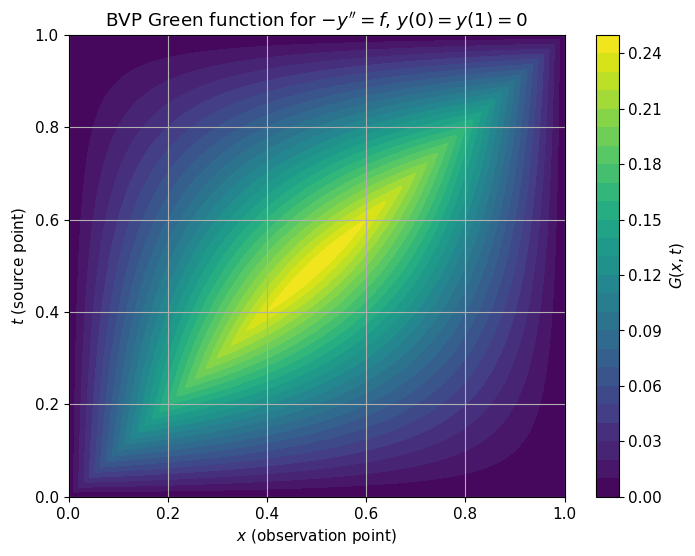

In [ ]:
x=np.linspace(0,1,260); t=np.linspace(0,1,260)
X,T=np.meshgrid(x,t)
G=np.where(X<=T,X*(1-T),T*(1-X))
plt.figure(figsize=(8,6))
plt.contourf(X,T,G,levels=25)
plt.xlabel('$x$ (observation point)'); plt.ylabel('$t$ (source point)')
plt.title(r"BVP Green function for $-y''=f$, $y(0)=y(1)=0$")
plt.colorbar(label='$G(x,t)$')
plt.show()

## 7. The Main Conceptual Picture

A Green's function converts a distributed forcing into a solution by superposition:

$$
\boxed{
\text{response}
=
\int
(\text{response to a unit source})
\times
(\text{source strength})
\,dt.
}
$$

For IVPs, this is closely related to convolution and impulse response in engineering and applied mathematics.

Green's functions are therefore not a completely separate method; they are a structured reformulation of variation of parameters that makes the input-response relationship explicit.

## Classroom Checkpoint

In [ ]:
show_48_checkpoint()

### Classroom Checkpoint 1

<IPython.core.display.Math object>

Explain the different roles of $x$ and $t$. Why is an IVP Green's kernel causal, with no contribution from $t>x$?

---

### Continue to the next section when ready.

## Section 4.9: Solving Systems of Linear Differential Equations by Elimination

## 1. Why a System Can Be Reduced to a Higher-Order Equation

A system of differential equations contains several unknown functions that evolve together.

For example,

$$
\boxed{
\begin{aligned}
x'&=a_{11}x+a_{12}y,\\
y'&=a_{21}x+a_{22}y.
\end{aligned}
}
$$

If one variable can be algebraically expressed in terms of the other variable and its derivative, then substitution can eliminate that variable and produce a higher-order scalar equation.

This is analogous to elimination in a system of algebraic equations, except that the operator

$$
D=\frac{d}{dt}
$$

plays the role of an algebraic symbol.

## 2. Differential-Operator Form

For constant-coefficient systems, write

$$
Dx=x',
\qquad
Dy=y'.
$$

A system can be expressed as

$$
\begin{aligned}
L_1(D)x+L_2(D)y&=f_1(t),\\
L_3(D)x+L_4(D)y&=f_2(t).
\end{aligned}
$$

Because polynomials in the constant-coefficient operator $D$ commute, we can apply operators to equations and combine them to eliminate one dependent variable.

This is the systematic operator version of the substitution method.

## 3. Detailed Example

Consider

$$
\boxed{
\begin{aligned}
x'&=x+2y,\\
y'&=-2x+y.
\end{aligned}
}
$$

We will eliminate $y$.

From the first equation,

$$
2y=x'-x.
$$

Therefore

$$
\boxed{y=\frac{x'-x}{2}.}
$$

Differentiate the first equation:

$$
x''=x'+2y'.
$$

Now use

$$
y'=-2x+y.
$$

Thus

$$
x''=x'+2(-2x+y).
$$

Substitute

$$
y=\frac{x'-x}{2}:
$$

$$
x''
=x'-4x+2\left(\frac{x'-x}{2}\right).
$$

Simplify:

$$
x''
=x'-4x+x'-x.
$$

Therefore

$$
x''=2x'-5x.
$$

Move all terms to one side:

$$
\boxed{x''-2x'+5x=0.}
$$

The characteristic equation is

$$
m^2-2m+5=0.
$$

Hence

$$
m=1\pm2i.
$$

Therefore

$$
\boxed{x(t)=e^t(c_1\cos2t+c_2\sin2t).}
$$

## 4. Recovering the Eliminated Variable

We should not solve a separate second-order equation for $y$ with two new arbitrary constants. The original system has only two degrees of freedom, so the same constants must determine both variables.

Use the recovery formula

$$
y=\frac{x'-x}{2}.
$$

Let

$$
x=e^t(c_1\cos2t+c_2\sin2t).
$$

Differentiate:

$$
x'
=e^t(c_1\cos2t+c_2\sin2t)
+e^t(-2c_1\sin2t+2c_2\cos2t).
$$

Therefore

$$
x'-x
=e^t(-2c_1\sin2t+2c_2\cos2t).
$$

Divide by $2$:

$$
\boxed{
y=e^t(-c_1\sin2t+c_2\cos2t).}
$$

The same two constants appear in both functions, as required.

## 5. Initial-Value Example

Suppose

$$
x(0)=1,
\qquad
y(0)=0.
$$

From

$$
x(0)=c_1,
$$

we obtain

$$
c_1=1.
$$

From

$$
y(0)=c_2,
$$

we obtain

$$
c_2=0.
$$

Hence

$$
\boxed{x(t)=e^t\cos2t,}
$$

and

$$
\boxed{y(t)=-e^t\sin2t.}
$$

The real part $1$ of the roots produces exponential growth, while the imaginary part $2$ produces rotation/oscillation between the two state variables.

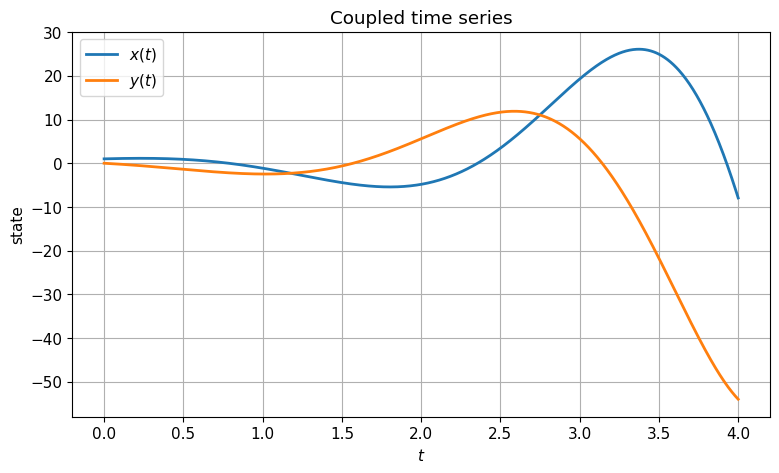

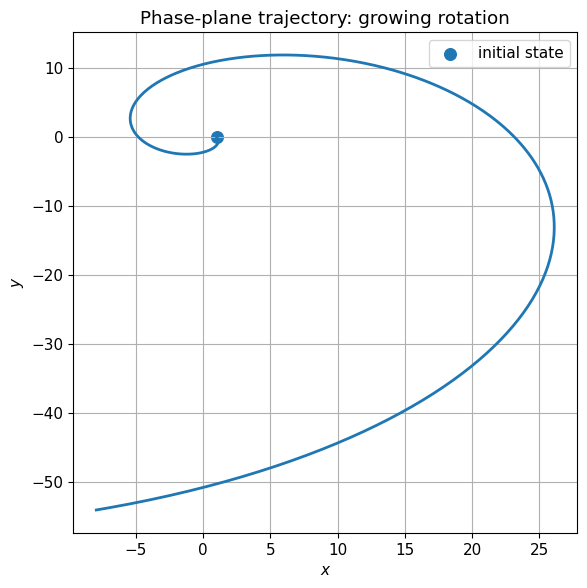

In [ ]:
t=np.linspace(0,4,900)
x=np.exp(t)*np.cos(2*t)
y=-np.exp(t)*np.sin(2*t)

plt.figure(figsize=(9,5))
plt.plot(t,x,label='$x(t)$',linewidth=2)
plt.plot(t,y,label='$y(t)$',linewidth=2)
plt.xlabel('$t$'); plt.ylabel('state'); plt.title('Coupled time series')
plt.legend(); plt.show()

plt.figure(figsize=(6.5,6.5))
plt.plot(x,y,linewidth=2)
plt.scatter([x[0]],[y[0]],s=70,label='initial state')
plt.xlabel('$x$'); plt.ylabel('$y$'); plt.title('Phase-plane trajectory: growing rotation')
plt.legend(); plt.show()

## 6. Systematic Elimination with Operators

Suppose

$$
\begin{aligned}
L_1(D)x+L_2(D)y&=f_1,\\
L_3(D)x+L_4(D)y&=f_2.
\end{aligned}
$$

To eliminate $y$ in a constant-coefficient system, apply $L_4(D)$ to the first equation and $L_2(D)$ to the second:

$$
L_4L_1x+L_4L_2y=L_4f_1,
$$

$$
L_2L_3x+L_2L_4y=L_2f_2.
$$

Subtract. Because

$$
L_4L_2=L_2L_4,
$$

the $y$ terms cancel:

$$
\boxed{(L_4L_1-L_2L_3)x=L_4f_1-L_2f_2.}
$$

A similar calculation eliminates $x$.

## 7. A Common Constant-Counting Mistake

If the system contains two first-order equations, its general solution should contain two independent arbitrary constants.

After eliminating one variable, we obtain a second-order scalar equation, which also contains two constants.

If we separately solve a second-order equation for the other variable and introduce two additional constants, we temporarily create four constants. Those constants cannot all be independent.

Substitution back into the original system imposes relations among them.

The safest workflow is often:

$$
\boxed{
\text{solve for one variable}
\longrightarrow
\text{recover the other from an original equation}.
}
$$

## Classroom Checkpoint

In [ ]:
show_49_checkpoint()

### Classroom Checkpoint 1

<IPython.core.display.Math object>

Eliminate $y$ and derive one second-order differential equation for $x(t)$. Show the recovery formula for $y$ as well.

---

### Continue to the next section when ready.

## Section 4.10: Nonlinear Higher-Order Differential Equations

## 1. What Changes in a Nonlinear Higher-Order Equation?

A higher-order equation is nonlinear if the dependent variable or its derivatives occur nonlinearly, for example through

$$
y^2,
\qquad
(y')^2,
\qquad
yy'',
\qquad
\sin y.
$$

Examples include

$$
y''+(y')^2=0
$$

and

$$
y''+y+y^3=0.
$$

Unlike homogeneous linear equations, nonlinear equations generally do **not** satisfy superposition.

If $y_1$ and $y_2$ are solutions of a nonlinear equation, there is usually no reason for

$$
c_1y_1+c_2y_2
$$

to be another solution.

## 2. Why Closed-Form General Solutions Are Harder

For linear equations, we have structural tools such as

- fundamental sets;
- characteristic equations;
- superposition;
- variation of parameters.

For nonlinear higher-order equations, there is no single general method of comparable scope.

Instead, we look for special structure. Two particularly useful patterns are

1. the dependent variable $y$ is missing;
2. the independent variable $x$ is missing.

Each pattern allows a substitution that reduces the order from two to one.

## 3. Case I: The Dependent Variable $y$ Is Missing

Suppose the equation has the form

$$
F(x,y',y'')=0.
$$

Because $y$ itself does not appear, set

$$
\boxed{u(x)=y'(x).}
$$

Then

$$
\boxed{u'(x)=y''(x).}
$$

The second-order equation becomes a first-order equation in $u(x)$.

After solving for $u$, return to

$$
y'=u(x)
$$

and integrate once more to recover $y$.

### Detailed example: $y''=(y')^2$

Set

$$
u=y'.
$$

Then

$$
u'=y''.
$$

The equation becomes

$$
\boxed{u'=u^2.}
$$

Before dividing by $u^2$, notice the equilibrium solution

$$
u=0.
$$

This corresponds to

$$
y'=0,
$$

so every constant function

$$
\boxed{y=C}
$$

is a solution of the original equation.

For nonzero $u$, separate variables:

$$
\frac{du}{u^2}=dx.
$$

Integrate:

$$
\int u^{-2}\,du=\int dx.
$$

Thus

$$
-\frac1u=x+C_1.
$$

Solve for $u$:

$$
u=-\frac{1}{x+C_1}.
$$

Since

$$
y'=u,
$$

we have

$$
y'=-\frac{1}{x+C_1}.
$$

Integrate again:

$$
y=-\ln|x+C_1|+C_2.
$$

Therefore the nonconstant family is

$$
\boxed{y=-\ln|x+C_1|+C_2,}
$$

together with the constant solutions recorded earlier.

## 4. Case II: The Independent Variable $x$ Is Missing

Now suppose the equation has the form

$$
F(y,y',y'')=0.
$$

The independent variable $x$ does not appear explicitly.

Set

$$
\boxed{u(y)=y'.}
$$

This time $u$ is viewed as a function of $y$, not directly as a function of $x$.

Use the chain rule:

$$
y''
=\frac{du}{dx}.
$$

Since $u=u(y)$,

$$
\frac{du}{dx}
=\frac{du}{dy}\frac{dy}{dx}.
$$

But

$$
\frac{dy}{dx}=y'=u.
$$

Therefore

$$
\boxed{y''=u\frac{du}{dy}.}
$$

This formula is the key to the reduction.

### Detailed example: $yy''=(y')^2$

Use

$$
u(y)=y'.
$$

Then

$$
y''=u\frac{du}{dy}.
$$

Substitute:

$$
yu\frac{du}{dy}=u^2.
$$

For $u\ne0$, divide by $u$:

$$
y\frac{du}{dy}=u.
$$

Separate:

$$
\frac{du}{u}=\frac{dy}{y}.
$$

Integrate:

$$
\ln|u|=\ln|y|+C.
$$

Exponentiating gives

$$
u=Cy.
$$

Return to

$$
u=y'.
$$

Thus

$$
y'=Cy.
$$

Separate and solve:

$$
\frac{dy}{y}=C\,dx.
$$

Therefore

$$
\ln|y|=Cx+C_2,
$$

and

$$
\boxed{y=Ae^{Cx}.}
$$

The division by $u$ excluded $u=0$, which corresponds to constant solutions. Those constant solutions are included in the final family when $C=0$, but the excluded case should still be consciously checked during the derivation.

## 5. Local Taylor Approximation for a Nonlinear IVP

When an explicit solution is unavailable, a Taylor expansion can provide a local approximation.

Consider

$$
\boxed{y''=-y-y^3,}
$$

with

$$
y(0)=1,
\qquad y'(0)=0.
$$

The Taylor series about $x=0$ is

$$
y(x)=y(0)+y'(0)x+\frac{y''(0)}{2!}x^2+\frac{y'''(0)}{3!}x^3+\cdots.
$$

The differential equation lets us compute the missing derivatives from the initial data.

First,

$$
y''(0)=-y(0)-y(0)^3=-1-1=-2.
$$

Differentiate the differential equation:

$$
y'''=-y'-3y^2y'.
$$

Factor:

$$
y'''=-(1+3y^2)y'.
$$

At $x=0$,

$$
y'(0)=0,
$$

so

$$
y'''(0)=0.
$$

Differentiate once more:

$$
y''''
=-(1+3y^2)y''-6y(y')^2.
$$

At $x=0$,

$$
y''''(0)
=-(1+3)(-2)-0
=8.
$$

Therefore the fourth-order Taylor approximation is

$$
\boxed{
y(x)\approx1-x^2+\frac13x^4.
}
$$

Continuing the recurrence gives

$$
y(x)=1-x^2+\frac13x^4-\frac{13}{90}x^6+\cdots.
$$

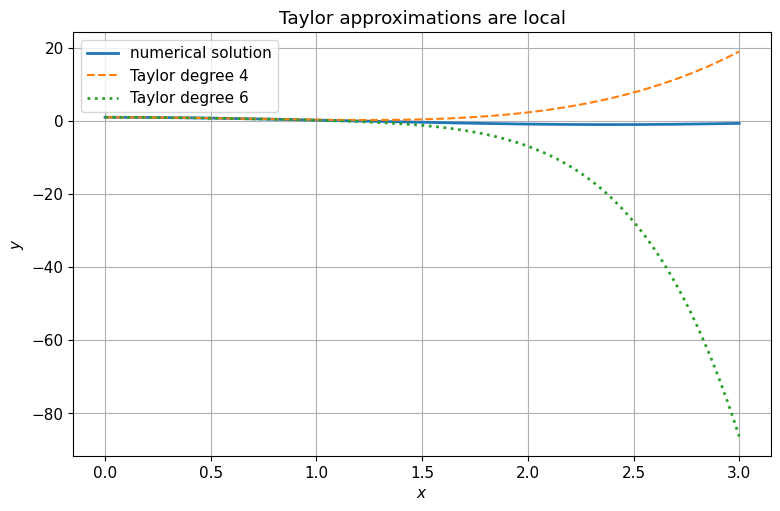

In [ ]:
def nonlinear_taylor_compare(T=3.0):
    def rhs(x,z):
        return [z[1],-z[0]-z[0]**3]
    xx=np.linspace(0,T,700)
    sol=solve_ivp(rhs,(0,T),[1,0],t_eval=xx,rtol=1e-10,atol=1e-12)
    p4=1-xx**2+xx**4/3
    p6=p4-13*xx**6/90
    plt.plot(xx,sol.y[0],linewidth=2,label='numerical solution')
    plt.plot(xx,p4,'--',label='Taylor degree 4')
    plt.plot(xx,p6,':',linewidth=2,label='Taylor degree 6')
    plt.xlabel('$x$'); plt.ylabel('$y$')
    plt.title('Taylor approximations are local')
    plt.legend(); plt.show()

nonlinear_taylor_compare()

## 6. Energy for an Autonomous Nonlinear Oscillator

Consider

$$
\boxed{y''+y+y^3=0.}
$$

Multiply by $y'$:

$$
y'y''+yy'+y^3y'=0.
$$

Recognize each term as a derivative:

$$
y'y''=\frac{d}{dx}\left(\frac12(y')^2\right),
$$

$$
yy'=\frac{d}{dx}\left(\frac12y^2\right),
$$

and

$$
y^3y'=\frac{d}{dx}\left(\frac14y^4\right).
$$

Therefore

$$
\frac{d}{dx}
\left[
\frac12(y')^2+\frac12y^2+\frac14y^4
\right]
=0.
$$

Thus the energy

$$
\boxed{
E=\frac12(y')^2+\frac12y^2+\frac14y^4
}
$$

is constant along a solution.

### Why this is useful

Even if we cannot solve explicitly for $y(x)$, the energy equation gives qualitative information.

For a fixed energy $E$, the phase-plane trajectory satisfies

$$
\frac12v^2+\frac12y^2+\frac14y^4=E,
\qquad v=y'.
$$

The trajectory remains on an energy level curve.

Unlike the linear oscillator

$$
y''+y=0,
$$

the nonlinear restoring force

$$
y+y^3
$$

becomes stronger at large amplitude, so the oscillation period depends on amplitude.

In [ ]:
def nonlinear_oscillator(A=1.0,T=30):
    def rhs(t,z):
        return [z[1],-z[0]-z[0]**3]
    sol=safe_solve(rhs,(0,T),[A,0],rtol=1e-9,atol=1e-11)
    y,v=sol.y
    E=.5*v**2+.5*y**2+.25*y**4

    plt.figure(figsize=(9,5))
    plt.plot(sol.t,y,linewidth=2)
    plt.xlabel('$t$'); plt.ylabel('$y(t)$')
    plt.title(f'Nonlinear oscillator, initial amplitude {A:.2f}')
    plt.show()

    plt.figure(figsize=(6.5,6.5))
    plt.plot(y,v,linewidth=2)
    plt.xlabel('$y$'); plt.ylabel("$y'$")
    plt.title('Closed energy-level trajectory')
    plt.show()

    print('Maximum numerical energy drift:',np.max(np.abs(E-E[0])))

interact(nonlinear_oscillator,A=FloatSlider(min=.2,max=3,step=.2,value=1,description='$A$'),T=IntSlider(min=10,max=60,step=5,value=30,description='time'));

interactive(children=(FloatSlider(value=1.0, description='$A$', max=3.0, min=0.2, step=0.2), IntSlider(value=3…

## 7. Method-Selection Summary

$$
\renewcommand{\arraystretch}{1.6}
\begin{array}{|c|c|}
\hline
\textbf{Structure} & \textbf{Useful reduction}\\
\hline
F(x,y',y'')=0\text{ with }y\text{ missing} & u(x)=y',\quad y''=u'\\
\hline
F(y,y',y'')=0\text{ with }x\text{ missing} & u(y)=y',\quad y''=u\,du/dy\\
\hline
\text{No convenient closed form} & \text{Taylor, numerical, or qualitative methods}\\
\hline
\text{Conservative autonomous oscillator} & \text{energy integral / phase plane}\\
\hline
\end{array}
$$

Nonlinear equations demand more structural recognition than formula memorization.

## Classroom Checkpoint

In [ ]:
show_410_checkpoint()

### Classroom Checkpoint 1

<IPython.core.display.Math object>

Which missing-variable reduction should be used? State the substitution and derive the replacement formula for $y''$ before transforming the equation.